In [51]:
# name: post_process
# date: 27/07/2026
# author: Toby Alexander

# description: 
# Post processing for glider data analysis. This script reads in the results of the non-linear fitting of the glider data, and performs further analysis and visualisation of the results.
# Includes data validation against soundings and ERA5 reanalysis data.

# required modules:
#   - Python 3.6+ (created with 3.10.19)
#   - cartopy
#   - cdsapi (https://cds.climate.copernicus.eu/how-to-api) for downloading ERA5 reanalysis data
#   - matplotlib
#   - numpy
#   - pandas
#   - sklearn (https://pypi.org/project/scikit-learn/) for DBSCAN clustering
#   - xarray (https://pypi.org/project/xarray/)

In [52]:
import cartopy.crs as ccrs 
import cartopy.feature as cfeature
import cdsapi   # for downloading ERA5 reanalysis data
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN  # DBSCAN - Density-Based Spatial Clustering of Applications with Noise
import xarray as xr     # working with netCDF files

# 1. Load in fitting results and radiosonde data

In [53]:
# Read in csv file of non-linear fitting results obtained from glider_analysis.ipynb.

root = ""
filename = "nonlinfit_results_FLRDDE434.csv"

filepath = root + filename

print(f"file id: {filename}")    

df = pd.read_csv(filepath)

file id: nonlinfit_results_FLRDDE434.csv


In [54]:
# Read in radiosonde data, sourced from the University of Wyoming radiosonde archive (http://weather.uwyo.edu/upperair/sounding.html). 
# The data is in CSV format, and contains the following columns:
# [time, longitude, latitude, pressure_hPa, geopotential height_m, temperature_C, dew point temperature_C, ice point temperature_C, relative humidity_%, humidity wrt ice_%, mixing ratio_g/kg, wind direction_degree, wind speed_m/s]

re_albemarle_folder = ""
re_albemarle_files = "2026032223-03238.csv"

# re_albemarle_data = pd.read_csv(f"{re_albemarle_folder}\\{re_albemarle_files}")
# radiosonde sample selected for 22-03-26 at 00:00 UTC at Albemarle, UK
re_albemarle_data = pd.read_csv(f"{re_albemarle_folder}{re_albemarle_files}")
print(f"Albemarle Radiosonde data for 22-03-2026 at 23:15 Z:")
print(re_albemarle_data)
print(f"******")

re_albemarle_data = re_albemarle_data.drop(index=0)  # drop first entry - always seems to be incomplete

re_albemarle_ws = re_albemarle_data["wind speed_m/s"].values.astype(float)
re_albemarle_alt = re_albemarle_data["geopotential height_m"].values.astype(float)
re_albemarle_wdir = re_albemarle_data["wind direction_degree"].values.astype(float)
re_albemarle_pres = re_albemarle_data["pressure_hPa"].values.astype(float)

# Select only data below 2km altitude, as this is the range of interest for the glider data.
mask_2km = re_albemarle_alt <= 2000
re_albemarle_ws = re_albemarle_ws[mask_2km]
re_albemarle_alt = re_albemarle_alt[mask_2km]
re_albemarle_wdir = re_albemarle_wdir[mask_2km]
re_albemarle_pres = re_albemarle_pres[mask_2km]

Albemarle Radiosonde data for 22-03-2026 at 23:15 Z:
                     time  longitude  latitude  pressure_hPa  \
0     2026-03-22 23:15:07    -1.8782   55.0192        1002.2   
1     2026-03-22 23:15:07    -1.8782   55.0192        1000.0   
2     2026-03-22 23:15:09    -1.8782   55.0192         999.7   
3     2026-03-22 23:15:11    -1.8781   55.0192         997.8   
4     2026-03-22 23:15:13    -1.8779   55.0192         996.7   
...                   ...        ...       ...           ...   
2545  2026-03-23 00:39:21    -1.0753   54.6311          16.8   
2546  2026-03-23 00:39:23    -1.0753   54.6310          16.7   
2547  2026-03-23 00:39:25    -1.0754   54.6310          16.7   
2548  2026-03-23 00:39:27    -1.0755   54.6309          16.7   
2549  2026-03-23 00:39:29    -1.0756   54.6308          16.6   

      geopotential height_m  temperature_C  dew point temperature_C  \
0                       142            4.0                     -0.0   
1                       160         

In [55]:
# Set lat and long of radiosonde launch site (in this case it was Albemarle, UK)
lat_albemarle = 55.019
lon_albemarle = -1.878

In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   id         7 non-null      str    
 1   timestamp  7 non-null      float64
 2   time       7 non-null      str    
 3   lat0       7 non-null      float64
 4   lon0       7 non-null      float64
 5   thermidx   7 non-null      float64
 6   win        7 non-null      str    
 7   omegaest   7 non-null      float64
 8   omegastd   7 non-null      float64
 9   Rxest      7 non-null      float64
 10  phixest    7 non-null      float64
 11  uest       7 non-null      float64
 12  ustd       7 non-null      float64
 13  x0est      7 non-null      float64
 14  Ryest      7 non-null      float64
 15  phiyest    7 non-null      float64
 16  vest       7 non-null      float64
 17  vstd       7 non-null      float64
 18  y0est      7 non-null      float64
 19  magU       7 non-null      float64
 20  stdmagU    7 non-null    

In [57]:
def stats_period_zdot(df):
    """
    Investigate how period and zdot change over each thermal; returns mean values and standard deviations.
    """
    results = []

    for (flight_id, therm_idx), thermal_df in df.groupby(['id', 'thermidx']):
        # separate lists of indices for each different thermal
        indices = thermal_df.index.tolist()
        # obtaining the omega values, grouping by the flight ID and thermal index
        omega = df.loc[indices, 'omegaest'].values
        P = abs(2 * np.pi / omega)
        # obtaining zdot values, grouping by the flight ID and thermal index
        zdot = df.loc[indices, 'zdot'].values

        results.append({
            'id': flight_id,
            'thermidx': therm_idx,
            'nbins': len(indices),
            'P_mean': P.mean(),
            'zdot_mean': zdot.mean(),
            'P_std': P.std(),
            'zdot_std': zdot.std()
        })

    return pd.DataFrame(results)

stats = stats_period_zdot(df)

In [58]:
stats
# df


,id,thermidx,nbins,P_mean,zdot_mean,P_std,zdot_std
0,FLRDDE434,0.0,1,31.253393,0.991845,0.000000,0.000000
1,FLRDDE434,1.0,5,35.169124,1.532328,3.169438,0.562818
2,FLRDDE434,2.0,1,33.904092,0.287811,0.000000,0.000000


# 2. Estimate upper bound of uncertainty in wind estimates from inter-bin variation

In [59]:
def calculate_upper_bound_errors(df):
    """
    Calculate weighted upper bound errors for discrete adjacent bin pairs
    within each thermal. Assumes an even number of bins per thermal.
    Effectively calculates the disagreement between adjacent bins in the same thermal soaring window, in an attempt to quantify the uncertainty in the wind estimates.
    """
    for col in ['u_upper', 'v_upper', 'magU_upper', 'dbUdeg_upper']:
        df[col] = np.nan
    
    params = [
        ('uest',  'ustd',    'u_upper'),
        ('vest',  'vstd',    'v_upper'),
    ]

    # Group by flight ID and thermal index, then iterate through each group.
    for (flight_id, therm_idx), thermal_df in df.groupby(['id', 'thermidx']):
        indices = thermal_df.index.tolist()
        print(indices)
        for i in range(0, len(indices) - 1, 2):
            idx1 = indices[i]
            idx2 = indices[i + 1]
            row1 = df.loc[idx1]
            row2 = df.loc[idx2]

            for est_col, std_col, out_col in params:
                print(est_col, std_col, out_col)
                print(f"est_col: {est_col}")
                print(row1[est_col])
                print(row2[est_col])
                # find the difference of the estimated wind speeds between the neighbouring rows
                delta = abs(row1[est_col] - row2[est_col])
                # determining the error of the difference between the two row estimated winds
                sigma_upper = delta / np.sqrt(2)  # Assuming n=2 for two measurements        

                df.at[idx1, out_col] = sigma_upper
                df.at[idx2, out_col] = sigma_upper

    return df

In [60]:
df_err = calculate_upper_bound_errors(df)

[0]
[1, 2, 3, 4, 5]
uest ustd u_upper
est_col: uest
7.020109651712932
9.121195798384482
vest vstd v_upper
est_col: vest
0.4479731048100913
0.4228876545218544
uest ustd u_upper
est_col: uest
7.528137245980494
6.782952411071606
vest vstd v_upper
est_col: vest
-0.8059390780181445
-0.2835376367150067
[6]


In [61]:
# propagate errors to magnitude and direction estimates
df['magU_upper'] = np.sqrt(df['uest']**2 * df['u_upper']**2 + df['vest']**2 * df['v_upper']**2) / df['magU']
df['dbUdeg_upper'] = np.sqrt(df['vest']**2 * df['u_upper']**2 + df['uest']**2 * df['v_upper']**2) / df['magU']**2

In [62]:
# Take the maximum of the standard deviation from fitting and interbin variation to get a combined error estimate for each parameter.
df['u_combined']    = np.maximum(df['ustd'],    df['u_upper'])
df['v_combined']    = np.maximum(df['vstd'],    df['v_upper'])
df['magU_combined'] = np.sqrt(df['uest']**2 * df['u_combined']**2 + df['vest']**2 * df['v_combined']**2) / df['magU']
df['bUdeg_combined']= np.sqrt(df['vest']**2 * df['u_combined']**2 + df['uest']**2 * df['v_combined']**2) / df['magU']**2

print(df)

          id     timestamp                              time       lat0  \
0  FLRDDE434  1.774194e+09         2026-03-22 15:36:30+00:00  56.193625   
1  FLRDDE434  1.774194e+09  2026-03-22 15:44:15.500000+00:00  56.194658   
2  FLRDDE434  1.774194e+09  2026-03-22 15:45:24.500000+00:00  56.195300   
3  FLRDDE434  1.774194e+09         2026-03-22 15:46:33+00:00  56.205125   
4  FLRDDE434  1.774194e+09         2026-03-22 15:47:42+00:00  56.221475   
5  FLRDDE434  1.774195e+09  2026-03-22 15:48:50.500000+00:00  56.228850   
6  FLRDDE434  1.774195e+09  2026-03-22 15:53:52.500000+00:00  56.193300   

       lon0  thermidx                             win  omegaest  omegastd  \
0 -3.318258       0.0   (np.int64(60), np.int64(122))  0.201040  0.001881   
1 -3.314108       1.0  (np.int64(357), np.int64(426)) -0.200155  0.002269   
2 -3.310275       1.0  (np.int64(426), np.int64(493)) -0.184995  0.000743   
3 -3.328058       1.0  (np.int64(493), np.int64(560)) -0.191666  0.000651   
4 -3.340242   

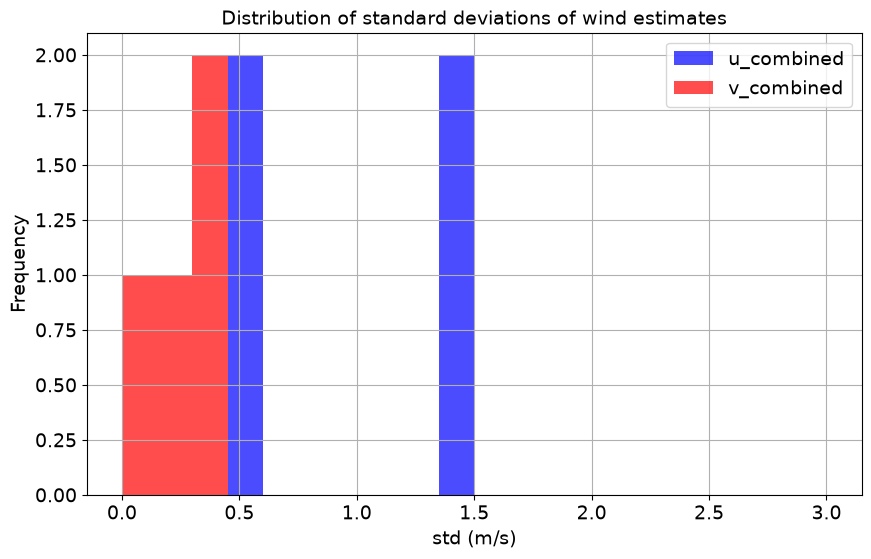

In [63]:
plt.figure(figsize=(10, 6))
plt.hist(df.u_combined, bins=20, range=[0, 3], color='blue', alpha=0.7, label='u_combined')
# plt.hist(df.magU_upper, bins=20, range=[0, 3], color='orange', alpha=0.7, label='magU_upper')
plt.hist(df.v_combined, bins=20, range=[0, 3], color='red', alpha=0.7, label='v_combined')
plt.xlabel('std (m/s)')
plt.ylabel('Frequency')
plt.title('Distribution of standard deviations of wind estimates')
plt.legend()
# plt.suptitle(f"ICAO24: {fid}")
plt.grid(True)
plt.show()

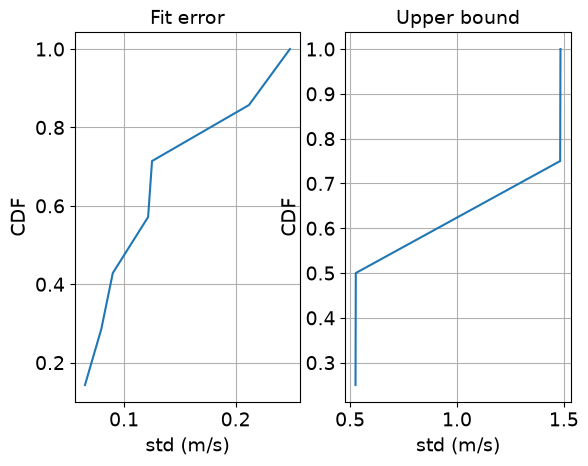

In [64]:
# Construct CDF plots for the model standard deviations of the wind estimates and the interbin variations.
fig, axes = plt.subplots(1, 2)

for ax, col, label in zip(axes, ['stdmagU', 'magU_upper'], ['Fit error', 'Upper bound']):
    sorted_vals = np.sort(df[col].dropna())
    cdf = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
    ax.plot(sorted_vals, cdf)
    ax.set_xlabel('std (m/s)')
    ax.set_ylabel('CDF')
    ax.set_title(label)
    ax.grid(True)
    

In [65]:
# Clean outliers from the dataframe based on standard deviation thresholds for the wind estimates.
# A standard deviation of 1m/s or greater from the model fitting was characterised by poor fits
# Interbin variation of 2.5m/s or greater was considered unphysical when compared to the wind shear observed by the colocated radiosonde data.
df_clean = df[(df['stdmagU'] < 1) & (df['magU_upper'] < 2.5)]

In [66]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 1 to 4
Data columns (total 34 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              4 non-null      str    
 1   timestamp       4 non-null      float64
 2   time            4 non-null      str    
 3   lat0            4 non-null      float64
 4   lon0            4 non-null      float64
 5   thermidx        4 non-null      float64
 6   win             4 non-null      str    
 7   omegaest        4 non-null      float64
 8   omegastd        4 non-null      float64
 9   Rxest           4 non-null      float64
 10  phixest         4 non-null      float64
 11  uest            4 non-null      float64
 12  ustd            4 non-null      float64
 13  x0est           4 non-null      float64
 14  Ryest           4 non-null      float64
 15  phiyest         4 non-null      float64
 16  vest            4 non-null      float64
 17  vstd            4 non-null      float64
 18  y0est

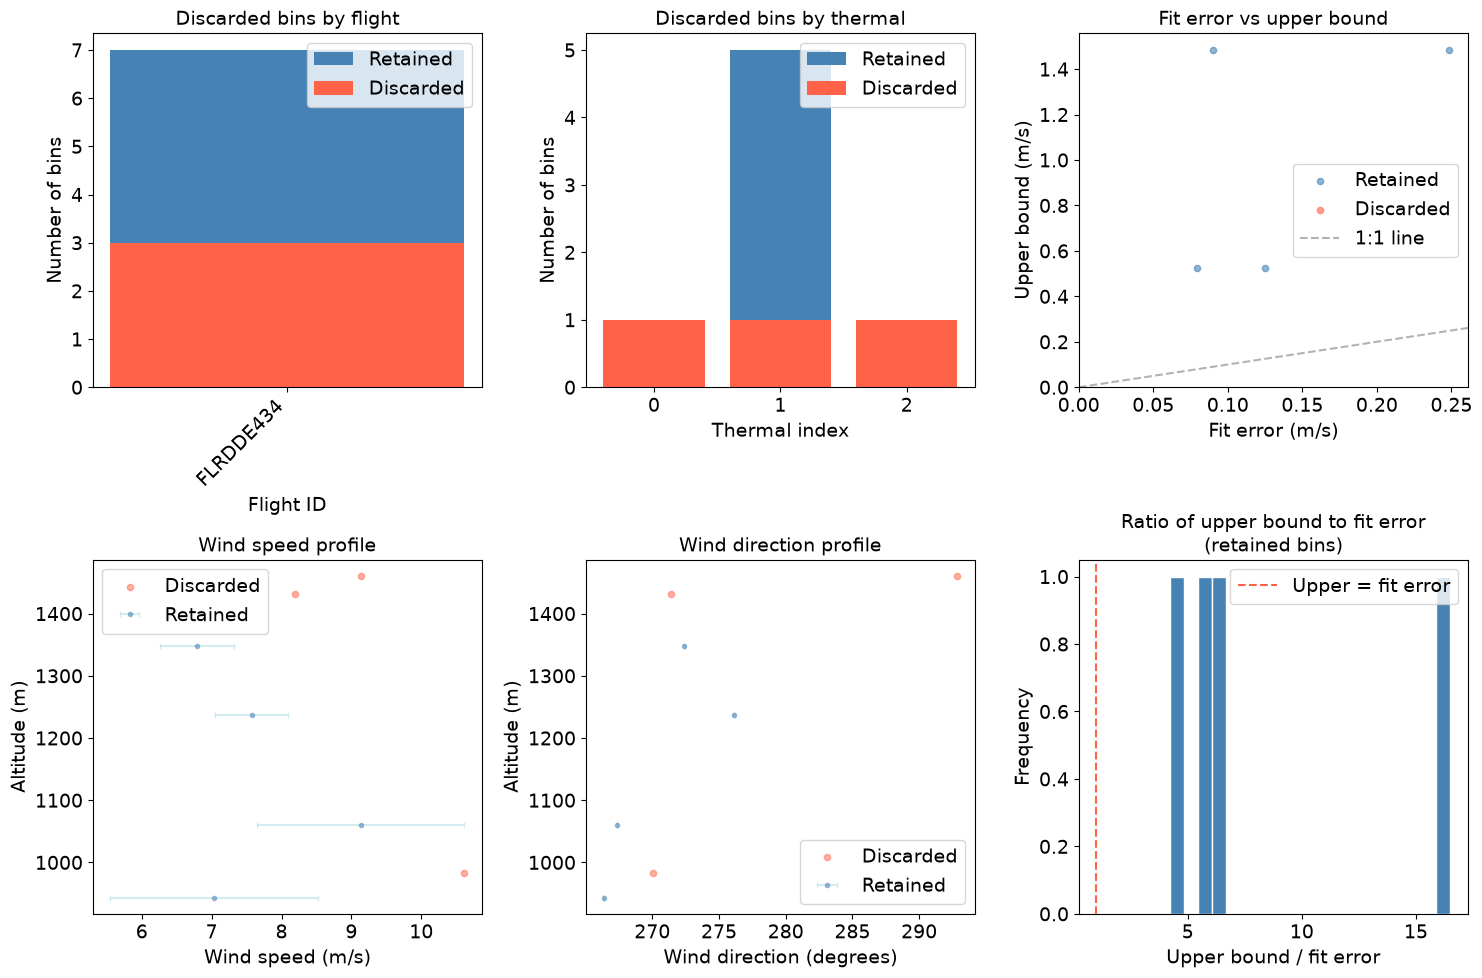

In [67]:
def plot_qc_diagnostics(df, df_clean, fit_col='stdmagU', upper_col='magU_upper', 
                         alt_col='zhat', flight_col='id', thermal_col='thermidx'):
    """
    Plot quality control diagnostics for the wind estimates, comparing retained and discarded bins based on the cleaning criteria.
    """
    discarded = df[~df.index.isin(df_clean.index)]
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # 1. Discarded bins by flight
    ax = axes[0, 0]
    flight_counts = df.groupby(flight_col).size()
    flight_counts_clean = df_clean.groupby(flight_col).size()
    flight_counts_discarded = flight_counts - flight_counts_clean.reindex(flight_counts.index, fill_value=0)
    x = np.arange(len(flight_counts))
    ax.bar(x, flight_counts, label='Retained', color='steelblue')
    ax.bar(x, flight_counts_discarded, label='Discarded', color='tomato')
    ax.set_xticks(x)
    ax.set_xticklabels(flight_counts.index, rotation=45, ha='right')
    ax.set_xlabel('Flight ID')
    ax.set_ylabel('Number of bins')
    ax.set_title('Discarded bins by flight')
    ax.legend()

    # 2. Discarded bins by thermal
    ax = axes[0, 1]
    therm_counts = df.groupby(thermal_col).size()
    therm_counts_clean = df_clean.groupby(thermal_col).size()
    therm_counts_discarded = therm_counts - therm_counts_clean.reindex(therm_counts.index, fill_value=0)
    x = np.arange(len(therm_counts))
    ax.bar(x, therm_counts, label='Retained', color='steelblue')
    ax.bar(x, therm_counts_discarded, label='Discarded', color='tomato')
    ax.set_xlabel('Thermal index')
    ax.set_ylabel('Number of bins')
    ax.set_title('Discarded bins by thermal')
    ax.legend()

    # 3. Fit error vs upper bound (retained vs discarded)
    ax = axes[0, 2]
    ax.scatter(df_clean[fit_col], df_clean[upper_col], 
               alpha=0.6, label='Retained', color='steelblue', s=20)
    ax.scatter(discarded[fit_col], discarded[upper_col], 
               alpha=0.6, label='Discarded', color='tomato', s=20)
    lim = max(df[fit_col].max(), df[upper_col].max()) * 1.05
    ax.plot([0, lim], [0, lim], 'k--', alpha=0.3, label='1:1 line')
    ax.set_xlabel('Fit error (m/s)')
    ax.set_ylabel('Upper bound (m/s)')
    ax.set_xlim(0, df[fit_col].max() * 1.05)
    ax.set_ylim(0, df[upper_col].max() * 1.05)
    ax.set_title('Fit error vs upper bound')
    ax.legend()

    # 4. Wind speed profile
    ax = axes[1, 0]
    ax.errorbar(df_clean['magU'], df_clean[alt_col], 
                xerr=df_clean[upper_col], fmt='o', alpha=0.5, 
                color='steelblue', ecolor='lightblue', capsize=2, markersize=3,
                label='Retained')
    ax.scatter(discarded['magU'], discarded[alt_col], 
               color='tomato', alpha=0.5, s=20, label='Discarded')
    ax.set_xlabel('Wind speed (m/s)')
    ax.set_ylabel('Altitude (m)')
    ax.set_title('Wind speed profile')
    ax.legend()

    # 5. Wind direction profile
    ax = axes[1, 1]
    ax.errorbar(df_clean['bUdeg'], df_clean[alt_col],
                xerr=df_clean['dbUdeg_upper'], fmt='o', alpha=0.5,
                color='steelblue', ecolor='lightblue', capsize=2, markersize=3,
                label='Retained')
    ax.scatter(discarded['bUdeg'], discarded[alt_col],
               color='tomato', alpha=0.5, s=20, label='Discarded')
    ax.set_xlabel('Wind direction (degrees)')
    ax.set_ylabel('Altitude (m)')
    ax.set_title('Wind direction profile')
    ax.legend()

    # 6. Fit error vs upper bound ratio
    ax = axes[1, 2]
    ratio = df_clean[upper_col] / df_clean[fit_col]
    ax.hist(ratio, bins=20, color='steelblue', edgecolor='white')
    ax.axvline(1, color='tomato', linestyle='--', label='Upper = fit error')
    ax.set_xlabel('Upper bound / fit error')
    ax.set_ylabel('Frequency')
    ax.set_title('Ratio of upper bound to fit error\n(retained bins)')
    ax.legend()

    fig.tight_layout()
    plt.show()

plot_qc_diagnostics(df, df_clean)

# 3. Visualise distribution of measurements, and cluster measurements by spatial and temporal distance

In [68]:
print(df_clean)

          id     timestamp                              time       lat0  \
1  FLRDDE434  1.774194e+09  2026-03-22 15:44:15.500000+00:00  56.194658   
2  FLRDDE434  1.774194e+09  2026-03-22 15:45:24.500000+00:00  56.195300   
3  FLRDDE434  1.774194e+09         2026-03-22 15:46:33+00:00  56.205125   
4  FLRDDE434  1.774194e+09         2026-03-22 15:47:42+00:00  56.221475   

       lon0  thermidx                             win  omegaest  omegastd  \
1 -3.314108       1.0  (np.int64(357), np.int64(426)) -0.200155  0.002269   
2 -3.310275       1.0  (np.int64(426), np.int64(493)) -0.184995  0.000743   
3 -3.328058       1.0  (np.int64(493), np.int64(560)) -0.191666  0.000651   
4 -3.340242       1.0  (np.int64(560), np.int64(624)) -0.165580  0.000855   

        Rxest  ...       zhat      zdot   u_upper   v_upper  magU_upper  \
1  106.613032  ...   943.2036  1.222815  1.485692  0.017738    1.482677   
2  121.013857  ...  1059.6372  1.952899  1.485692  0.017738    1.484098   
3  123.121247

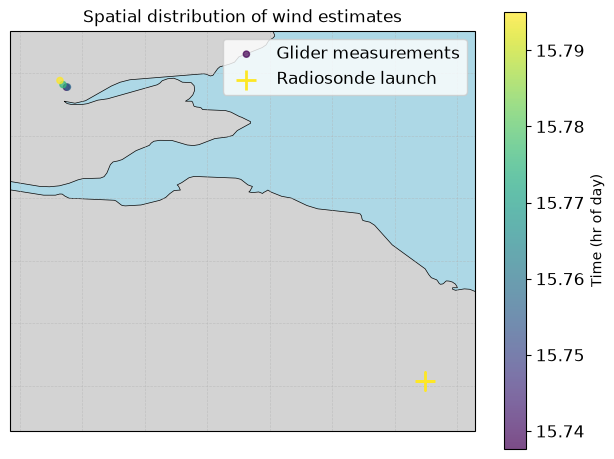

In [69]:
def plot_clusters_map(df, lat_col='lat0', lon_col='long0',
                      sonde_lat=None, sonde_lon=None, sonde_time=10.75,
                      show_grid_labels=False):
    """
    Plot the spatial distribution of wind estimates on a map, optionally including the location of a radiosonde launch.
    """
    plt.rcParams.update({
        'font.size': 12,
        'axes.titlesize': 12,
        'axes.labelsize': 10,
        'xtick.labelsize': 10,
        'ytick.labelsize': 12,
        'legend.fontsize': 12,
    })

    fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})
    
    ax.add_feature(cfeature.LAND, facecolor='lightgrey')
    ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5, linestyle='--')
    ax.add_feature(cfeature.RIVERS, linewidth=0.3)
    
    margin = 0.2
    # expand extent to include sonde location
    all_lons = list(df[lon_col]) + ([sonde_lon] if sonde_lon is not None else [])
    all_lats = list(df[lat_col]) + ([sonde_lat] if sonde_lat is not None else [])
    
    lon_min = min(all_lons) - margin
    lon_max = max(all_lons) + margin
    lat_min = min(all_lats) - margin
    lat_max = max(all_lats) + margin
    # crs=PlateCarree(): interpret the four passed extent co-ordinates as long and lats in degrees
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

    # workaround added until a new version of Cartopy is available (for pixi env)
    # current version has troubles with adding the grid lines to lat/lon plot
    if show_grid_labels:
        gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
        gl.top_labels = False
        gl.right_labels = False
    else:
        ax.gridlines(draw_labels=False, linewidth=0.5, alpha=0.5, linestyle='--')

    # t_hours = df['timestamp'] % (3600 * 24) / 3600
    t_seconds_per_day = df['timestamp'] % (3600 * 24)
    t_hours = t_seconds_per_day / 3600
    vmin, vmax = t_hours.min(), t_hours.max()

    scatter = ax.scatter(df[lon_col], df[lat_col],
                         c=t_hours, cmap='viridis', s=20, alpha=0.7,
                         vmin=vmin, vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         label='Glider measurements')

    # optionally add radiosonde launch point
    if sonde_lat is not None and sonde_lon is not None:
        ax.scatter(sonde_lon, sonde_lat,
                   c=[sonde_time], cmap='viridis', vmin=vmin, vmax=vmax,
                   s=200, marker='+', linewidths=2,
                   transform=ccrs.PlateCarree(),
                   label='Radiosonde launch', zorder=5)
    
    cbar = fig.colorbar(scatter, ax=ax)
    cbar.set_label('Time (hr of day)')
    ax.set_title('Spatial distribution of wind estimates')
    ax.legend(loc='upper right')
    fig.tight_layout()
    plt.show()

# call with radiosonde location
# sondes in UK launched at 11:15 Z (Camborne & Lerwick only) and 23:15 Z
plot_clusters_map(df_clean, lat_col='lat0', lon_col='lon0',
                  sonde_lat=55.019, sonde_lon=-1.878, sonde_time=23.25)

Found 1 clusters, 0 unassigned points


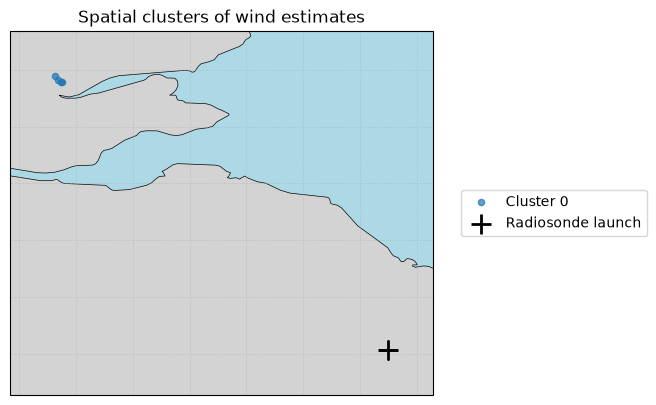

In [70]:
def cluster_measurements(df, eps_km=50, min_samples=5, 
                          lat_col='lat', lon_col='lon'):
    """
    Cluster measurements by spatial proximity using DBSCAN.
    eps_km: maximum distance between points in the same cluster (km)
    min_samples: minimum number of points to form a cluster
    """
    lat_col = "lat0"
    lon_col = "lon0"
    # convert lat/lon to radians for haversine metric
    coords = np.deg2rad(df[[lat_col, lon_col]].values)
    # eps in radians (earth radius ~6371km)
    eps_rad = eps_km / 6371.0
    
    db = DBSCAN(eps=eps_rad, min_samples=min_samples, metric='haversine')
    df['cluster'] = db.fit_predict(coords)

    # above step combines below two steps to fit the model and find cluster labels in one step
    # clustering = db.fit(coords)
    # df['cluster'] = clustering.labels_
    
    # -1 means noise (not assigned to any cluster)
    n_clusters = len(set(df['cluster'])) - (1 if -1 in df['cluster'].values else 0)
    n_noise = (df['cluster'] == -1).sum()
    print(f"Found {n_clusters} clusters, {n_noise} unassigned points")
    
    return df

def plot_clusters_map(df, lat_col='lat0', lon_col='lon0',
                      sonde_lat=None, sonde_lon=None, show_grid_labels=False):

    plt.rcParams.update({
        'font.size': 12,
        'axes.titlesize': 12,
        'axes.labelsize': 12,
        'xtick.labelsize': 12,
        'ytick.labelsize': 12,
        'legend.fontsize': 10,
    })

    fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})
    
    ax.add_feature(cfeature.LAND, facecolor='lightgrey')
    ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5, linestyle='--')
    ax.add_feature(cfeature.RIVERS, linewidth=0.3)
    
    margin = 0.2
    # expand extent to include sonde location
    all_lons = list(df[lon_col]) + ([sonde_lon] if sonde_lon is not None else [])
    all_lats = list(df[lat_col]) + ([sonde_lat] if sonde_lat is not None else [])

    lon_min = min(all_lons) - margin
    lon_max = max(all_lons) + margin
    lat_min = min(all_lats) - margin
    lat_max = max(all_lats) + margin
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    
    if show_grid_labels:
        gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
        gl.top_labels = False
        gl.right_labels = False
    else:
        ax.gridlines(draw_labels=False, linewidth=0.5, alpha=0.5, linestyle='--')

    # plot clusters
    clusters = sorted(df['cluster'].unique())
    cmap = plt.get_cmap('tab10', len(clusters))
    
    for i, cluster_id in enumerate(clusters):
        mask = df['cluster'] == cluster_id
        label = f'Cluster {cluster_id}' if cluster_id != -1 else 'Unassigned'
        color = 'grey' if cluster_id == -1 else cmap(i)
        ax.scatter(df[mask][lon_col], df[mask][lat_col],
                   color=color, label=label, s=20, alpha=0.7,
                   transform=ccrs.PlateCarree())

    # optionally add radiosonde launch point
    if sonde_lat is not None and sonde_lon is not None:
        ax.scatter(sonde_lon, sonde_lat,
                   color='black', s=200, marker='+', linewidths=2,
                   transform=ccrs.PlateCarree(),
                   label='Radiosonde launch', zorder=5)

    ax.legend(bbox_to_anchor=(1.05, 0.5), loc='center left')
    ax.set_title('Spatial clusters of wind estimates')
    fig.tight_layout()
    plt.show()


## run
df_clean = cluster_measurements(df_clean, eps_km=20, min_samples=4)
# call with radiosonde location
plot_clusters_map(df_clean, lat_col='lat0', lon_col='lon0',
                  sonde_lat=55.019, sonde_lon=-1.878)

In [71]:
print(df_clean.groupby('cluster').size())

cluster
0    4
dtype: int64


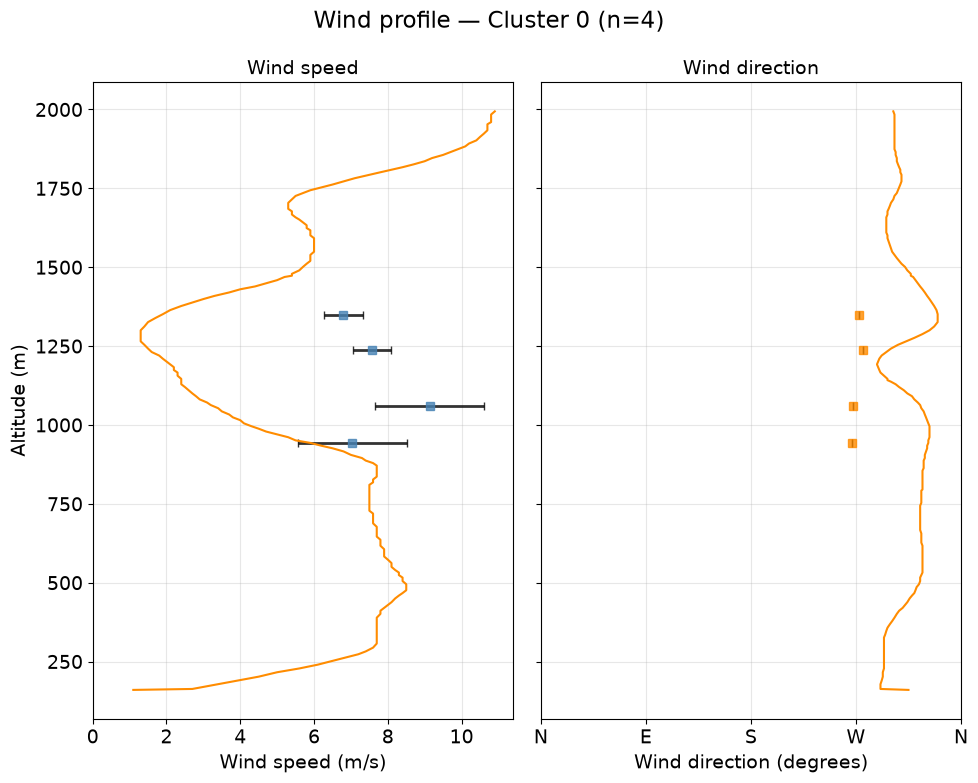

In [72]:
def plot_wind_profiles(df, alt_col='zhat', speed_col='magU', dir_col='bUdeg',
                       speed_err_col='magU_combined', dir_err_col='bUdeg_combined',
                       cluster_col='cluster'):
    """
    Plot wind speed and direction profiles for each cluster of measurements, including error bars and comparison with radiosonde data.
    """
    clusters = sorted([c for c in df[cluster_col].unique() if c != -1])
    
    for cluster_id in clusters:
        cluster_df = df[df[cluster_col] == cluster_id].copy()

        plt.rcParams.update({
        'font.size': 14,          # default for everything
        'axes.titlesize': 14,     # subplot titles
        'axes.labelsize': 14,     # x and y labels
        'xtick.labelsize': 14,    # tick labels
        'ytick.labelsize': 14,
        'legend.fontsize': 14,
        })

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8), sharey=True)
        fig.suptitle(f'Wind profile — Cluster {cluster_id} (n={len(cluster_df)})')
        
        # wind speed
        ax1.errorbar(cluster_df[speed_col], cluster_df[alt_col],
                     xerr=cluster_df[speed_err_col],
                     fmt='s', markersize=6, capsize=3, linewidth=2,
                     color='steelblue', ecolor='k',
                     alpha=0.8)
        ax1.plot(re_albemarle_ws, re_albemarle_alt, label='Radiosonde (albemarle)', color='darkorange')
        ax1.set_xlabel('Wind speed (m/s)')
        ax1.set_ylabel('Altitude (m)')
        ax1.set_title('Wind speed')
        ax1.grid(True, alpha=0.3)
        ax1.set_xlim(left=0)

        # wind direction
        ax2.errorbar(cluster_df[dir_col], cluster_df[alt_col],
                     xerr=cluster_df[dir_err_col],
                     fmt='s', markersize=6, capsize=3, linewidth=2,
                     color='darkorange', ecolor='k',
                     alpha=0.8)
        ax2.plot(re_albemarle_wdir, re_albemarle_alt, label='Radiosonde (albemarle)', color='darkorange')
        ax2.set_xlabel('Wind direction (degrees)')
        ax2.set_title('Wind direction')
        ax2.grid(True, alpha=0.3)
        ax2.set_xlim(0, 360)
        ax2.set_xticks([0, 90, 180, 270, 360])
        ax2.set_xticklabels(['N', 'E', 'S', 'W', 'N'])

        fig.tight_layout()
        plt.show()

plot_wind_profiles(df_clean)

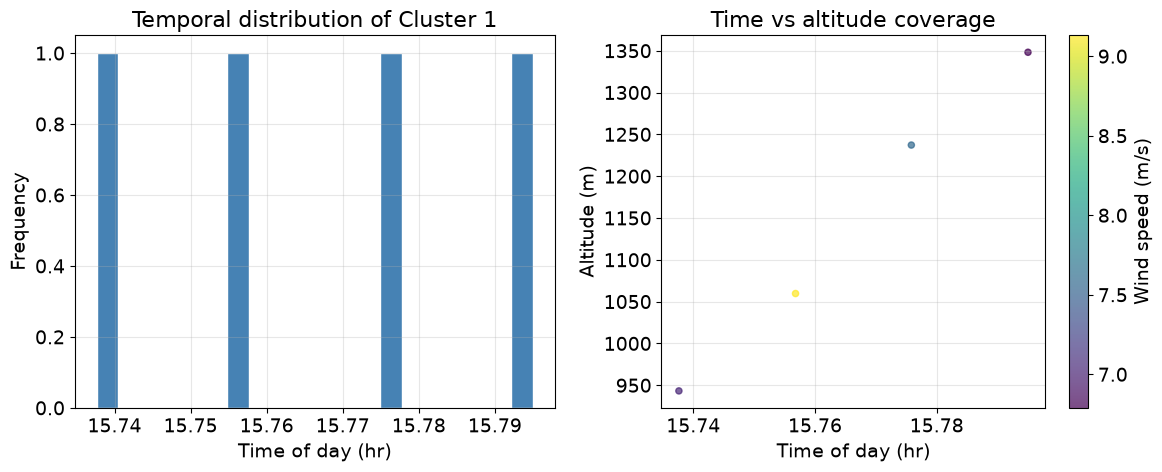

Cluster 1: 4 points
Time range: 15.7 - 15.8 hr
Altitude range: 943 - 1348 m


In [73]:
# Plot temporal distribution of measurements in cluster 1, and scatter of time vs altitude to see temporal coverage at each height.

alt_col = 'zhat'

cluster1 = df_clean[df_clean['cluster'] == 0].copy()
cluster1_time = cluster1['timestamp'] % (3600*24) / 3600
cluster1['timestamp_hr'] = cluster1_time


plt.rcParams.update({
    'font.size': 16,          # default for everything
    'axes.titlesize': 16,     # subplot titles
    'axes.labelsize': 14,     # x and y labels
    'xtick.labelsize': 14,    # tick labels
    'ytick.labelsize': 14,
    'legend.fontsize': 16,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# time distribution
axes[0].hist(cluster1['timestamp_hr'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Time of day (hr)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Temporal distribution of Cluster 1')
axes[0].grid(True, alpha=0.3)

# scatter of time vs altitude to see temporal coverage at each height
scatter = axes[1].scatter(cluster1['timestamp_hr'], cluster1[alt_col],
                           c=cluster1['magU'], cmap='viridis', s=20, alpha=0.7)
cbar = fig.colorbar(scatter, ax=axes[1])
cbar.set_label('Wind speed (m/s)')
axes[1].set_xlabel('Time of day (hr)')
axes[1].set_ylabel('Altitude (m)')
axes[1].set_title('Time vs altitude coverage')
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

print(f"Cluster 1: {len(cluster1)} points")
print(f"Time range: {cluster1['timestamp_hr'].min():.1f} - {cluster1['timestamp_hr'].max():.1f} hr")
print(f"Altitude range: {cluster1[alt_col].min():.0f} - {cluster1[alt_col].max():.0f} m")

In [74]:
# def subcluster_by_time(df, cluster_id, breaks, cluster_col='cluster'):
#     """
#     Split a cluster into time-based sub-clusters using manual time breaks.
#     breaks: list of hour values defining the boundaries e.g. [12.5, 15.0]
#     """
#     mask = df[cluster_col] == cluster_id

#     df.loc[mask, 'subcluster'] = pd.cut(
#         df.loc[mask, 'timestamp_hr'],
#         bins=[-np.inf] + breaks + [np.inf],
#         labels=[f'{cluster_id}a', f'{cluster_id}b', f'{cluster_id}c']
#     )
#     return df

def subcluster_by_time(df, cluster_id, breaks, cluster_col='cluster'):
    """
    Split a cluster into time-based sub-clusters using manual time breaks.
    breaks: list of hour values defining the boundaries e.g. [12.5, 15.0]
    Example: cluster_id=0, breaks=[12.5, 15.0]
    """
    # Ensure the 'timestamp_hr' column exists
    if 'timestamp_hr' not in df.columns:
        df['timestamp_hr'] = (df['timestamp'] % (24 * 3600)) / 3600

    # Keep only the rows in the target cluster
    mask = df[cluster_col] == cluster_id

    # Preparing new 'subcluster' column in DataFrame
    df['subcluster'] = pd.Series(np.nan, index=df.index, dtype='object')

    # If the cluster is present, assign subcluster labels
    if mask.any():
        labels = [f'{cluster_id}a', f'{cluster_id}b', f'{cluster_id}c']
        df.loc[mask, 'subcluster'] = pd.cut(
            df.loc[mask, 'timestamp_hr'],
            bins=[-np.inf] + list(breaks) + [np.inf],
            labels=labels
        )

    return df
 
df_clean['timestamp_hr'] = df_clean['timestamp'] % (3600*24) / 3600

df_clean = subcluster_by_time(df_clean, cluster_id=0, breaks=[12.5, 15.0])

# check counts
print(df_clean[df_clean['cluster'] == 0].groupby('subcluster').size())

subcluster
0c    4
dtype: int64


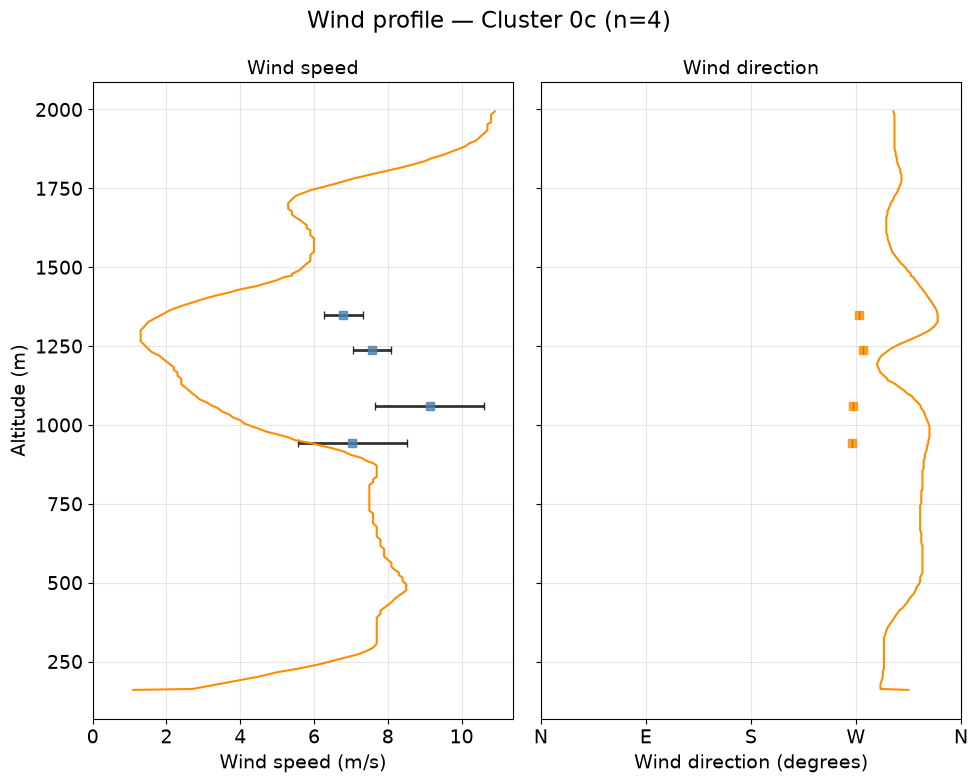

In [75]:
plot_wind_profiles(df_clean[df_clean['cluster'] == 0],
                   cluster_col='subcluster')

# 4. Quantitative comparison between glider measurements and radiosonde

In [76]:
df_sonde = pd.DataFrame({'magU': re_albemarle_ws, 'direction': re_albemarle_wdir, 'alt': re_albemarle_alt, 'pres': re_albemarle_pres})

In [77]:
# Convert wind speed and direction measured by sonde to u and v components for comparison with glider estimates.
theta_rad = np.deg2rad(df_sonde['direction'])  # met convention, degrees
df_sonde['u'] = -df_sonde['magU'] * np.sin(theta_rad)
df_sonde['v'] = -df_sonde['magU'] * np.cos(theta_rad)

In [78]:
# reconstruct magU and direction from converted u/v and compare to original
magU_check = np.sqrt(df_sonde['u']**2 + df_sonde['v']**2)
dir_check = (270 - np.rad2deg(np.arctan2(df_sonde['v'], df_sonde['u']))) % 360

print(np.allclose(magU_check, df_sonde['magU']))        # should be True
print(np.allclose(dir_check, df_sonde['direction']))    # should be True

True
True


In [81]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.deg2rad, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

def compare_to_radiosonde(df_glider, df_sonde,
                           alt_col='alt', zhat_col='zhat',
                           u_col='uest', v_col='vest',
                           u_err_col='u_combined', v_err_col='v_combined',
                           glider_lat_col='lat0', glider_lon_col='lon0',
                           sonde_lat=None, sonde_lon=None,
                           sonde_time=None):
    """
    Compare glider wind estimates to nearest radiosonde measurement by altitude.
    Treats radiosonde as truth. Reports fraction of measurements within 1 and 2 sigma.
    """
    results = []

    for _, row in df_glider.iterrows():
        # find nearest radiosonde measurement by altitude
        alt_diff = np.abs(df_sonde[alt_col] - row[zhat_col])
        nearest = df_sonde.loc[alt_diff.idxmin()]

        # compute normalised residuals
        du = row[u_col] - nearest['u']
        dv = row[v_col] - nearest['v']

        # normalise by glider error (treating sonde as truth)
        zu = du / row[u_err_col]
        zv = dv / row[v_err_col]

        # horizontal distance from glider to sonde launch point (km)
        if sonde_lat is not None and sonde_lon is not None:
            horiz_dist_km = haversine_km(row[glider_lat_col], row[glider_lon_col],
                                          sonde_lat, sonde_lon)
            # total 3D distance in metres (combining horizontal and vertical separation)
            vert_diff_m = abs(row[zhat_col] - nearest[alt_col])
            total_dist_m = np.sqrt((horiz_dist_km * 1000)**2 + vert_diff_m**2)
        else:
            horiz_dist_km = np.nan
            total_dist_m  = np.nan

        # time separation in hours
        if sonde_time is not None:
            time_sep_hr = abs(row['timestamp_hr'] - sonde_time)
        else:
            time_sep_hr = np.nan

        results.append({
            'alt':           row[zhat_col],
            'du':            du,
            'dv':            dv,
            'zu':            zu,
            'zv':            zv,
            'sonde_alt':     nearest[alt_col],
            'alt_diff':      alt_diff.min(),
            'horiz_dist_km': horiz_dist_km,
            'total_dist_m':  total_dist_m,
            'time_sep_hr':   time_sep_hr,
        })

    results_df = pd.DataFrame(results)
    print(f"Results df from glider row - radiosonde differences")
    print(results_df)

    # compute fractions within 1 and 2 sigma
    for comp, z_col in [('u', 'zu'), ('v', 'zv')]:
        within_1s = (np.abs(results_df[z_col]) <= 1).mean()
        within_2s = (np.abs(results_df[z_col]) <= 2).mean()
        within_3s = (np.abs(results_df[z_col]) <= 3).mean()
        within_5s = (np.abs(results_df[z_col]) <= 5).mean()
        print(f"{comp}: {within_1s*100:.1f}% within 1σ, {within_2s*100:.1f}% within 2σ, "
              f"{within_3s*100:.1f}% within 3σ, {within_5s*100:.1f}% within 5σ")

    print(f"\nExpected (Gaussian): 68.3% within 1σ, 95.4% within 2σ")
    print(f"\nMean horizontal separation: {results_df['horiz_dist_km'].mean():.1f} km")
    print(f"Mean total 3D separation:   {results_df['total_dist_m'].mean():.0f} m")
    print(f"Mean time separation:       {results_df['time_sep_hr'].mean():.2f} hr")

    return results_df

# call with sonde location and launch time
results_df = compare_to_radiosonde(df_clean[df_clean['subcluster'] == '0c'], df_sonde,
                                    sonde_lat=55.019, sonde_lon=-1.878,
                                    sonde_time=23.25)  # 23:15 in decimal hours

Results df from glider row - radiosonde differences
         alt        du        dv         zu         zv  sonde_alt  alt_diff  \
0   943.2036  4.250227  5.657364   2.860772  28.573433      943.0    0.2036   
1  1059.6372  7.285751  3.044174   4.903944  49.343937     1063.0    3.3628   
2  1237.1832  6.229099 -0.055939  11.821599  -0.151435     1242.0    4.8168   
3  1348.1304  6.133114  1.501878  11.639439   4.065794     1351.0    2.8696   

   horiz_dist_km   total_dist_m  time_sep_hr  
0     158.819835  158819.834676     7.512361  
1     158.741616  158741.615578     7.493194  
2     160.268278  160268.277994     7.474167  
3     162.188500  162188.500223     7.455000  
u: 0.0% within 1σ, 0.0% within 2σ, 25.0% within 3σ, 50.0% within 5σ
v: 25.0% within 1σ, 25.0% within 2σ, 25.0% within 3σ, 50.0% within 5σ

Expected (Gaussian): 68.3% within 1σ, 95.4% within 2σ

Mean horizontal separation: 160.0 km
Mean total 3D separation:   160005 m
Mean time separation:       7.48 hr


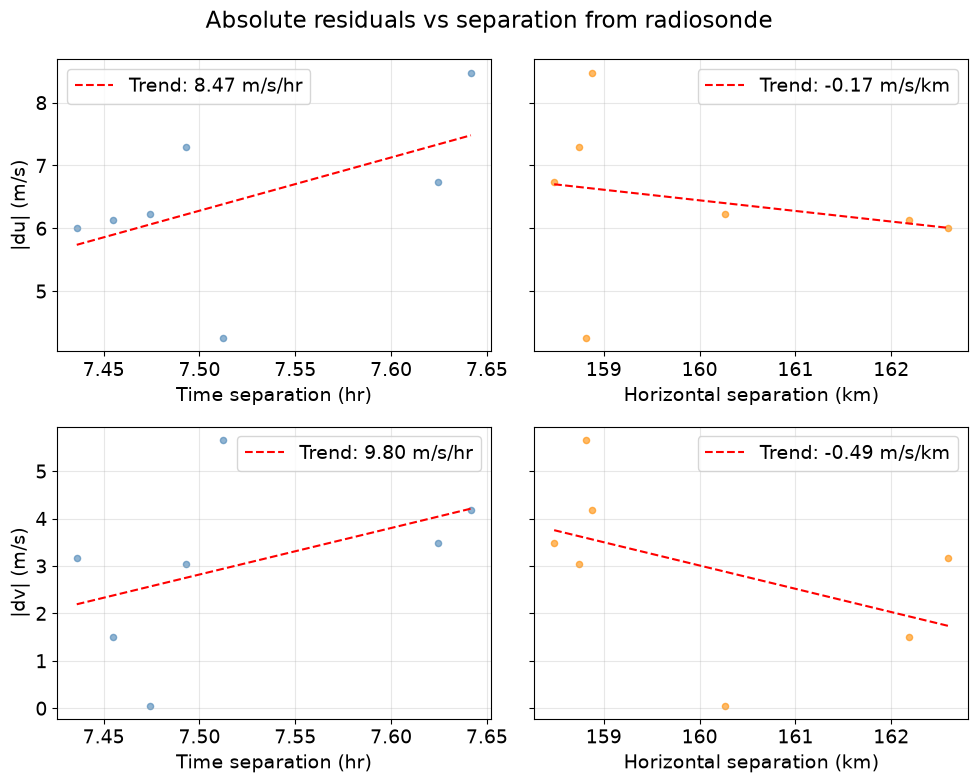

In [197]:
def plot_residuals_vs_separation(results_df):
    """
    Plot absolute residuals of u and v components against time separation and horizontal distance from radiosonde.
    We are trying to see if the disagreement between glider and radiosonde wind estimates increases with time or distance from the radiosonde launch point.
    """
    fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharey='row')
    fig.suptitle('Absolute residuals vs separation from radiosonde')

    for col, (ax1, ax2), label in zip(
        ['du', 'dv'],
        [(axes[0, 0], axes[0, 1]), (axes[1, 0], axes[1, 1])],
        ['|du| (m/s)', '|dv| (m/s)']
    ):
        abs_resid = results_df[col].abs()

        # vs time separation
        ax1.scatter(results_df['time_sep_hr'], abs_resid,
                    alpha=0.6, color='steelblue', s=20)
        ax1.set_xlabel('Time separation (hr)')
        ax1.set_ylabel(label)
        ax1.grid(True, alpha=0.3)

        # add linear trend
        mask = results_df['time_sep_hr'].notna() & abs_resid.notna()
        if mask.sum() > 2:
            z = np.polyfit(results_df.loc[mask, 'time_sep_hr'], abs_resid[mask], 1)
            x = np.linspace(results_df['time_sep_hr'].min(),
                            results_df['time_sep_hr'].max(), 100)
            ax1.plot(x, np.polyval(z, x), 'r--', linewidth=1.5, label=f'Trend: {z[0]:.2f} m/s/hr')
            ax1.legend()

        # vs horizontal distance
        ax2.scatter(results_df['horiz_dist_km'], abs_resid,
                    alpha=0.6, color='darkorange', s=20)
        ax2.set_xlabel('Horizontal separation (km)')
        ax2.grid(True, alpha=0.3)

        # add linear trend
        mask = results_df['horiz_dist_km'].notna() & abs_resid.notna()
        if mask.sum() > 2:
            # obtaining best-fit parameters for the straight-line fit
            z = np.polyfit(results_df.loc[mask, 'horiz_dist_km'], abs_resid[mask], 1)
            x = np.linspace(results_df['horiz_dist_km'].min(),
                            results_df['horiz_dist_km'].max(), 100)
            # plotting the straight-line fit, using the best-fit parameters derived above
            ax2.plot(x, np.polyval(z, x), 'r--', linewidth=1.5, label=f'Trend: {z[0]:.2f} m/s/km')
            ax2.legend()

    fig.tight_layout()
    plt.show()

plot_residuals_vs_separation(results_df)

Results df from glider row - radiosonde differences
         alt        du        dv         zu         zv  sonde_alt  alt_diff  \
0   943.2036  4.250227  5.657364   2.860772  28.573433      943.0    0.2036   
1  1059.6372  7.285751  3.044174   4.903944  49.343937     1063.0    3.3628   
2  1237.1832  6.229099 -0.055939  11.821599  -0.151435     1242.0    4.8168   
3  1348.1304  6.133114  1.501878  11.639439   4.065794     1351.0    2.8696   

   horiz_dist_km   total_dist_m  time_sep_hr  
0     158.819835  158819.834676     7.512361  
1     158.741616  158741.615578     7.493194  
2     160.268278  160268.277994     7.474167  
3     162.188500  162188.500223     7.455000  
u: 0.0% within 1σ, 0.0% within 2σ, 25.0% within 3σ, 50.0% within 5σ
v: 25.0% within 1σ, 25.0% within 2σ, 25.0% within 3σ, 50.0% within 5σ

Expected (Gaussian): 68.3% within 1σ, 95.4% within 2σ

Mean horizontal separation: 160.0 km
Mean total 3D separation:   160005 m
Mean time separation:       7.48 hr
***********
 

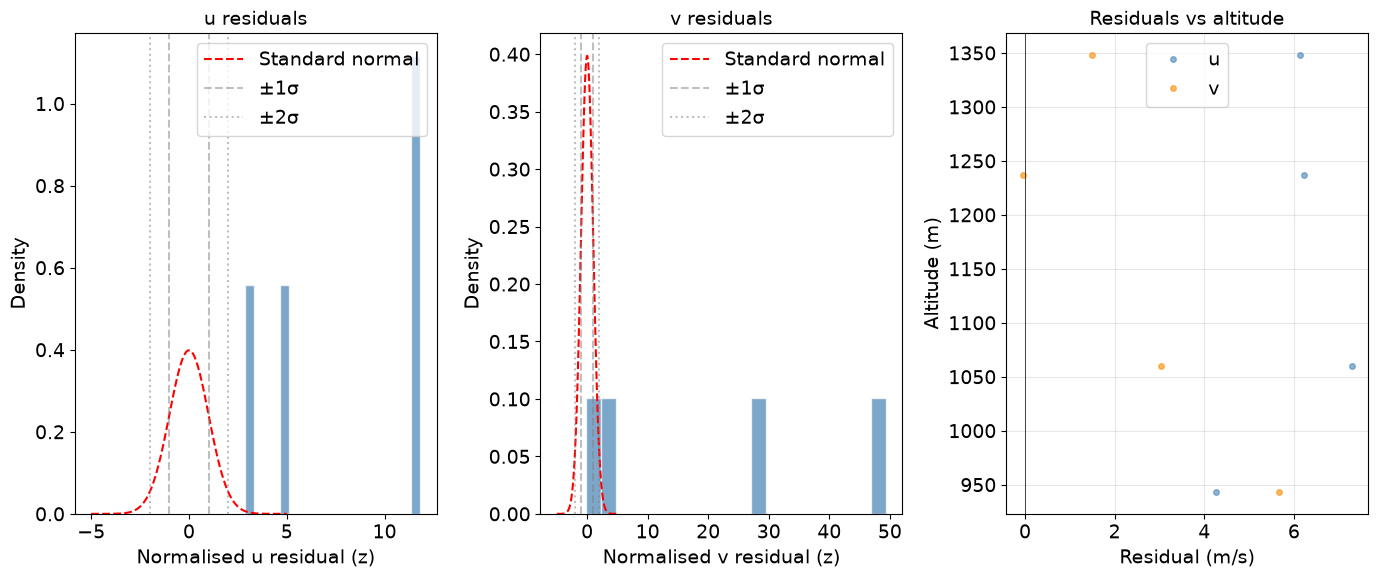

In [83]:
def plot_sonde_comparison(results_df):
    fig, axes = plt.subplots(1, 3, figsize=(14, 6))

    # normalised residual distributions
    for ax, z_col, label in zip(axes[:2], ['zu', 'zv'], ['u', 'v']):
        ax.hist(results_df[z_col], bins=20, density=True,
                color='steelblue', edgecolor='white', alpha=0.7)
        # overlay standard normal for reference
        x = np.linspace(-5, 5, 100)
        ax.plot(x, np.exp(-x**2/2) / np.sqrt(2*np.pi),
                'r--', label='Standard normal')
        ax.axvline(-1, color='grey', linestyle='--', alpha=0.5)
        ax.axvline( 1, color='grey', linestyle='--', alpha=0.5, label='±1σ')
        ax.axvline(-2, color='grey', linestyle=':',  alpha=0.5)
        ax.axvline( 2, color='grey', linestyle=':',  alpha=0.5, label='±2σ')
        ax.set_xlabel(f'Normalised {label} residual (z)')
        ax.set_ylabel('Density')
        ax.set_title(f'{label} residuals')
        ax.legend()

    # residuals vs altitude
    axes[2].plot(results_df['du'], results_df['alt'], 'o',
                 color='steelblue', alpha=0.6, markersize=4, label='u')
    axes[2].plot(results_df['dv'], results_df['alt'], 'o',
                 color='darkorange', alpha=0.6, markersize=4, label='v')
    axes[2].axvline(0, color='k', linewidth=0.5)
    axes[2].set_xlabel('Residual (m/s)')
    axes[2].set_ylabel('Altitude (m)')
    axes[2].set_title('Residuals vs altitude')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()

# run
# results_df = compare_to_radiosonde(df_clean, df_sonde)
results_sonde = compare_to_radiosonde(df_clean[df_clean['subcluster'] == '0c'], df_sonde,
                                    sonde_lat=55.019, sonde_lon=-1.878,
                                    sonde_time=23.25)
print("***********")
print(results_sonde)
print("***********")
plot_sonde_comparison(results_sonde)

Results df from glider row - radiosonde differences
         alt        du        dv         zu         zv  sonde_alt  alt_diff  \
0   943.2036  4.250227  5.657364   2.860772  28.573433      943.0    0.2036   
1  1059.6372  7.285751  3.044174   4.903944  49.343937     1063.0    3.3628   
2  1237.1832  6.229099 -0.055939  11.821599  -0.151435     1242.0    4.8168   
3  1348.1304  6.133114  1.501878  11.639439   4.065794     1351.0    2.8696   

   horiz_dist_km   total_dist_m  time_sep_hr  
0     158.819835  158819.834676     7.512361  
1     158.741616  158741.615578     7.493194  
2     160.268278  160268.277994     7.474167  
3     162.188500  162188.500223     7.455000  
u: 0.0% within 1σ, 0.0% within 2σ, 25.0% within 3σ, 50.0% within 5σ
v: 25.0% within 1σ, 25.0% within 2σ, 25.0% within 3σ, 50.0% within 5σ

Expected (Gaussian): 68.3% within 1σ, 95.4% within 2σ

Mean horizontal separation: 160.0 km
Mean total 3D separation:   160005 m
Mean time separation:       7.48 hr


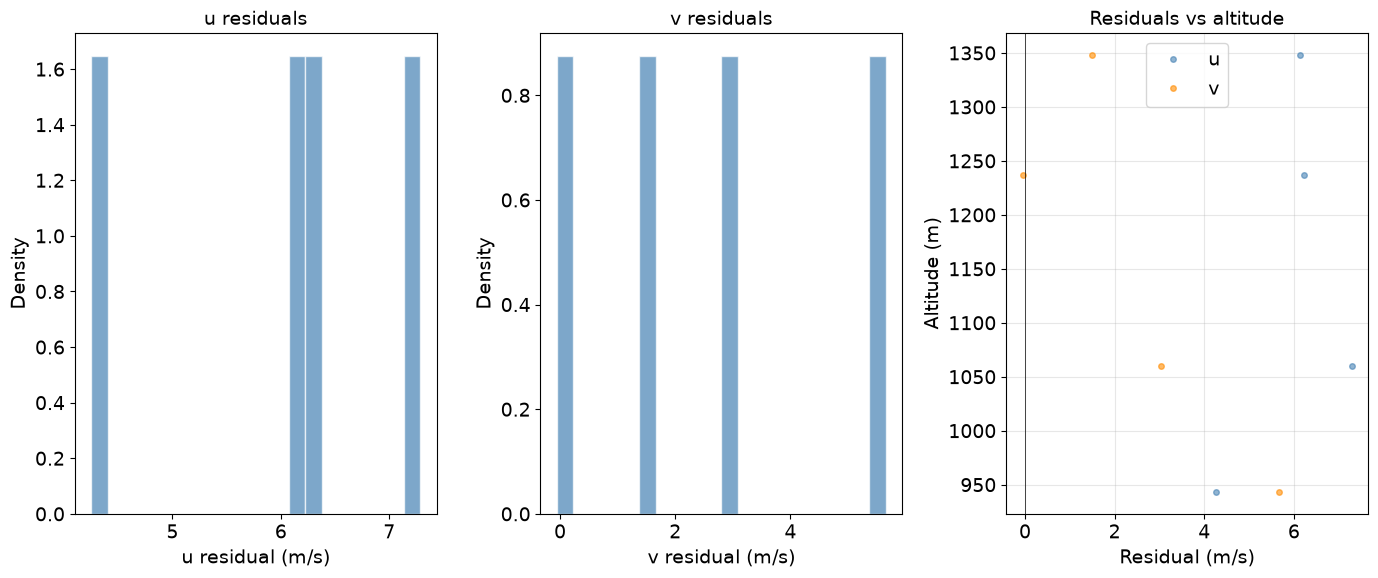

In [84]:
def plot_sonde_comparison_abs(results_df):
    fig, axes = plt.subplots(1, 3, figsize=(14, 6))

    # absolute residual distributions
    for ax, z_col, label in zip(axes[:2], ['du', 'dv'], ['u', 'v']):
        ax.hist(results_df[z_col], bins=20, density=True,
                color='steelblue', edgecolor='white', alpha=0.7)
        # overlay standard normal for reference
        x = np.linspace(-5, 5, 100)
        # ax.plot(x, np.exp(-x**2/2) / np.sqrt(2*np.pi),
        #         'r--', label='Standard normal')
        # ax.axvline(-1, color='grey', linestyle='--', alpha=0.5)
        # ax.axvline( 1, color='grey', linestyle='--', alpha=0.5, label='±1σ')
        # ax.axvline(-2, color='grey', linestyle=':',  alpha=0.5)
        # ax.axvline( 2, color='grey', linestyle=':',  alpha=0.5, label='±2σ')
        ax.set_xlabel(f'{label} residual (m/s)')
        ax.set_ylabel('Density')
        ax.set_title(f'{label} residuals')
        # ax.legend()

    # residuals vs altitude
    axes[2].plot(results_df['du'], results_df['alt'], 'o',
                 color='steelblue', alpha=0.6, markersize=4, label='u')
    axes[2].plot(results_df['dv'], results_df['alt'], 'o',
                 color='darkorange', alpha=0.6, markersize=4, label='v')
    axes[2].axvline(0, color='k', linewidth=0.5)
    axes[2].set_xlabel('Residual (m/s)')
    axes[2].set_ylabel('Altitude (m)')
    axes[2].set_title('Residuals vs altitude')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()

# run
results_sonde = compare_to_radiosonde(df_clean[df_clean['subcluster'] == '0c'], df_sonde,
                                    sonde_lat=55.019, sonde_lon=-1.878,
                                    sonde_time=23.25)
plot_sonde_comparison_abs(results_sonde)

In [85]:
results_sonde.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   alt            4 non-null      float64
 1   du             4 non-null      float64
 2   dv             4 non-null      float64
 3   zu             4 non-null      float64
 4   zv             4 non-null      float64
 5   sonde_alt      4 non-null      float64
 6   alt_diff       4 non-null      float64
 7   horiz_dist_km  4 non-null      float64
 8   total_dist_m   4 non-null      float64
 9   time_sep_hr    4 non-null      float64
dtypes: float64(10)
memory usage: 452.0 bytes


# 5. Quantitative comparison between glider measurements and ERA5

In [86]:
# Connect to the Copernicus Climate Data Store (CDS) API to retrieve additional data if needed.
import cdsapi
c = cdsapi.Client()
print("Connected successfully")

2026-10-07 12:50:53,698 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**


Connected successfully


In [87]:
# Two example retrievals of ERA5 reanalysis data for wind components at various pressure levels. Uncomment and modify as needed to retrieve data.
# The file will be saved in the current working directory.

c = cdsapi.Client()
c.retrieve('reanalysis-era5-pressure-levels', {
    'variable': ['u_component_of_wind', 'v_component_of_wind'],
    'pressure_level': ['800', '825', '850', '875', '900', '925', '950', '975', '1000'],
    'year': '2026', 'month': '03', 'day': '22',
    'time': ['14:00', '15:00', '16:00', '17:00', '18:00', '19:00', '20:00', '21:00', '22:00', '23:00'],
    'area': [57.0, -4.0, 55.0, -1.0],  # N/W/S/E bounding box
    'data_format': 'netcdf'
}, 'era5_winds_22mar.nc')

c = cdsapi.Client()
c.retrieve('reanalysis-era5-pressure-levels', {
    'variable': ['u_component_of_wind', 'v_component_of_wind'],
    'pressure_level': ['800', '825', '850', '875', '900', '925', '950', '975', '1000'],
    'year': '2026', 'month': '03', 'day': '23',
    'time': ['00:00'],
    'area': [57.0, -4.0, 55.0, -1.0],  # N/W/S/E bounding box
    'data_format': 'netcdf'
}, 'era5_winds_23mar_00.nc')

# c = cdsapi.Client()
# c.retrieve('reanalysis-era5-pressure-levels', {
#     'variable': ['u_component_of_wind', 'v_component_of_wind'],
#     'pressure_level': ['800', '825', '850', '875', '900', '925', '950', '975'],
#     'year': '2023', 'month': '07', 'day': '02',
#     'time': ['09:00', '10:00', '11:00', '12:00', '13:00', '14:00', '15:00', '16:00', '17:00', '18:00'],
#     'area': [52.1, 5.5, 51.0, 7.3],  # N/W/S/E with 0.2 degree margin
#     'data_format': 'netcdf'
# }, 'era5_winds_02jul.nc')

2026-10-07 12:51:29,329 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-07 12:51:29,780 INFO Request ID is 93972076-f364-4007-a439-dace1d871765
2026-10-07 12:51:29,877 INFO status has been updated to accepted
2026-10-07 12:51:48,434 INFO status has been updated to running
2026-10-07 12:52:51,194 INFO status has been updated to successful


4672cec7ff49cffe4f3dddf71f3f4007.nc:   0%|          | 0.00/87.2k [00:00<?, ?B/s]

2026-10-07 12:52:54,073 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
2026-10-07 12:52:54,310 INFO Request ID is de935476-0a0d-4ce5-80fb-0cfc2d5e0ebb
2026-10-07 12:52:54,422 INFO status has been updated to accepted
2026-10-07 12:53:19,182 INFO status has been updated to running
2026-10-07 12:53:47,903 INFO status has been updated to successful


d2d2c34df7d89cc67d4877147e6840d8.nc:   0%|          | 0.00/42.2k [00:00<?, ?B/s]

'era5_winds_23mar_00.nc'

In [88]:
# Use xarray to open both ERA5 netCDF files and combine them into a single dataset for interpolation.
ds_22 = xr.open_dataset('era5_winds_22mar.nc')
ds_23 = xr.open_dataset('era5_winds_23mar_00.nc')
ds = xr.concat([ds_22, ds_23], dim='valid_time').sortby('valid_time')
print(ds)

<xarray.Dataset> Size: 93kB
Dimensions:         (valid_time: 11, pressure_level: 9, latitude: 9,
                     longitude: 13)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 88B 2026-03-22T14:00:00 ... 2...
    expver          (valid_time) <U4 176B '0001' '0001' '0001' ... '0001' '0001'
  * pressure_level  (pressure_level) float64 72B 1e+03 975.0 ... 825.0 800.0
  * latitude        (latitude) float64 72B 57.0 56.75 56.5 ... 55.5 55.25 55.0
  * longitude       (longitude) float64 104B -4.0 -3.75 -3.5 ... -1.5 -1.25 -1.0
    number          int64 8B 0
Data variables:
    u               (valid_time, pressure_level, latitude, longitude) float32 46kB ...
    v               (valid_time, pressure_level, latitude, longitude) float32 46kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Cen

In [91]:
print(ds)
print(ds.coords)
print(ds['u'].dims)

<xarray.Dataset> Size: 93kB
Dimensions:         (valid_time: 11, pressure_level: 9, latitude: 9,
                     longitude: 13)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 88B 2026-03-22T14:00:00 ... 2...
    expver          (valid_time) <U4 176B '0001' '0001' '0001' ... '0001' '0001'
  * pressure_level  (pressure_level) float64 72B 1e+03 975.0 ... 825.0 800.0
  * latitude        (latitude) float64 72B 57.0 56.75 56.5 ... 55.5 55.25 55.0
  * longitude       (longitude) float64 104B -4.0 -3.75 -3.5 ... -1.5 -1.25 -1.0
    number          int64 8B 0
Data variables:
    u               (valid_time, pressure_level, latitude, longitude) float32 46kB ...
    v               (valid_time, pressure_level, latitude, longitude) float32 46kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Cen

In [90]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 1 to 4
Data columns (total 37 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              4 non-null      str    
 1   timestamp       4 non-null      float64
 2   time            4 non-null      str    
 3   lat0            4 non-null      float64
 4   lon0            4 non-null      float64
 5   thermidx        4 non-null      float64
 6   win             4 non-null      str    
 7   omegaest        4 non-null      float64
 8   omegastd        4 non-null      float64
 9   Rxest           4 non-null      float64
 10  phixest         4 non-null      float64
 11  uest            4 non-null      float64
 12  ustd            4 non-null      float64
 13  x0est           4 non-null      float64
 14  Ryest           4 non-null      float64
 15  phiyest         4 non-null      float64
 16  vest            4 non-null      float64
 17  vstd            4 non-null      float64
 18  y0est

In [92]:
# find what altitude each pressure level of ERA5 corresponds to in the radiosonde
idx = (df_sonde['pres'] - 975).abs().idxmin()
print(df_sonde.loc[idx, ['pres', 'alt']])

idx = (df_sonde['pres'] - 950).abs().idxmin()
print(df_sonde.loc[idx, ['pres', 'alt']])

idx = (df_sonde['pres'] - 925).abs().idxmin()
print(df_sonde.loc[idx, ['pres', 'alt']])

idx = (df_sonde['pres'] - 900).abs().idxmin()
print(df_sonde.loc[idx, ['pres', 'alt']])

idx = (df_sonde['pres'] - 875).abs().idxmin()
print(df_sonde.loc[idx, ['pres', 'alt']])

idx = (df_sonde['pres'] - 850).abs().idxmin()
print(df_sonde.loc[idx, ['pres', 'alt']])

idx = (df_sonde['pres'] - 825).abs().idxmin()
print(df_sonde.loc[idx, ['pres', 'alt']])

idx = (df_sonde['pres'] - 800).abs().idxmin()
print(df_sonde.loc[idx, ['pres', 'alt']])

pres    974.9
alt     368.0
Name: 19, dtype: float64
pres    949.5
alt     583.0
Name: 41, dtype: float64
pres    925.0
alt     795.0
Name: 63, dtype: float64
pres     900.1
alt     1015.0
Name: 88, dtype: float64
pres     874.9
alt     1242.0
Name: 113, dtype: float64
pres     850.0
alt     1473.0
Name: 134, dtype: float64
pres     824.6
alt     1715.0
Name: 160, dtype: float64
pres     800.0
alt     1960.0
Name: 186, dtype: float64


In [ ]:
print(df_clean)

print(df_clean['zhat'])

186
          id     timestamp                              time       lat0  \
1  FLRDDE434  1.774194e+09  2026-03-22 15:44:15.500000+00:00  56.194658   
2  FLRDDE434  1.774194e+09  2026-03-22 15:45:24.500000+00:00  56.195300   
3  FLRDDE434  1.774194e+09         2026-03-22 15:46:33+00:00  56.205125   
4  FLRDDE434  1.774194e+09         2026-03-22 15:47:42+00:00  56.221475   

       lon0  thermidx                             win  omegaest  omegastd  \
1 -3.314108       1.0  (np.int64(357), np.int64(426)) -0.200155  0.002269   
2 -3.310275       1.0  (np.int64(426), np.int64(493)) -0.184995  0.000743   
3 -3.328058       1.0  (np.int64(493), np.int64(560)) -0.191666  0.000651   
4 -3.340242       1.0  (np.int64(560), np.int64(624)) -0.165580  0.000855   

        Rxest  ...   v_upper  magU_upper  dbUdeg_upper  u_combined  \
1  106.613032  ...  0.017738    1.482677      0.013684    1.485692   
2  121.013857  ...  0.017738    1.484098      0.007781    1.485692   
3  123.121247  ...  0.36

975
943.2036
31.79639999999995
era5_point <xarray.Dataset> Size: 56B
Dimensions:         ()
Coordinates:
    number          int64 8B 0
    pressure_level  float64 8B 900.0
    latitude        float64 8B 56.19
    longitude       float64 8B -3.314
    valid_time      datetime64[us] 8B 2026-03-22T15:44:15.500000
Data variables:
    u               float64 8B 8.558
    v               float64 8B -1.874
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-07T11:52 GRIB to CDM+CF via cfgrib-0.9.1...
u_era5: 8.558464025973267
v_era5: -1.8743736077492565
975
1059.6372
84.6371999999999
era5_point <xarray.Dataset> Size: 56B
Dimensions:         ()
Coordinates:
    number          int64 8B 0
    pressure_level  float64 8B 900.0
    latitude   

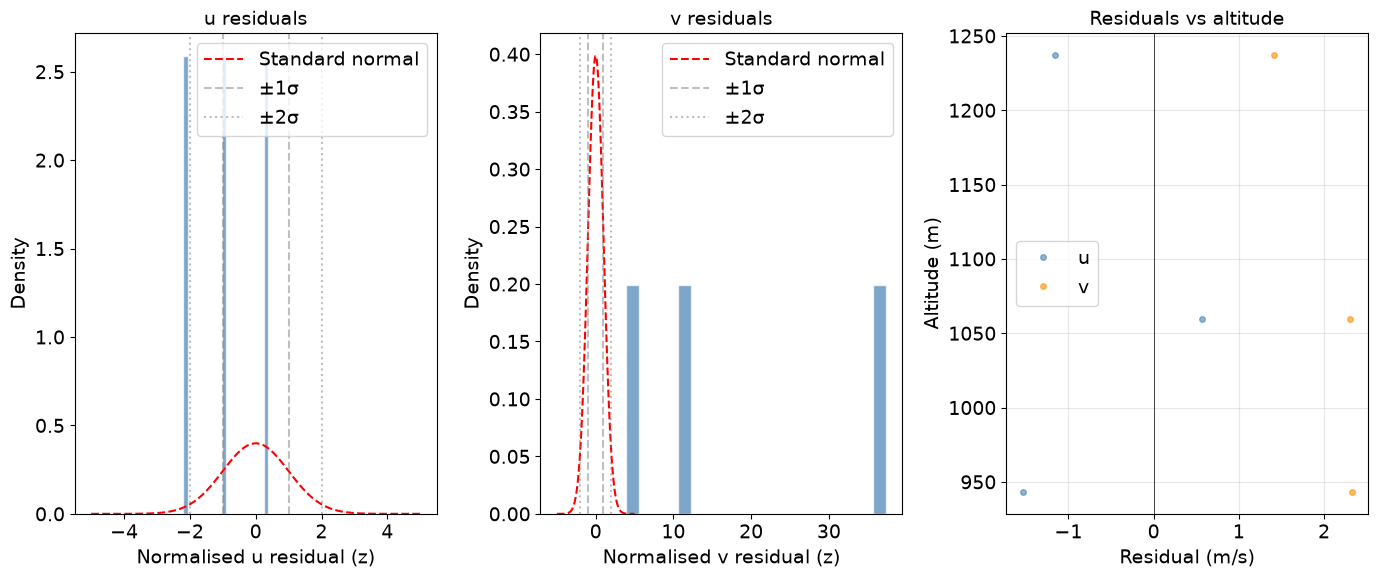

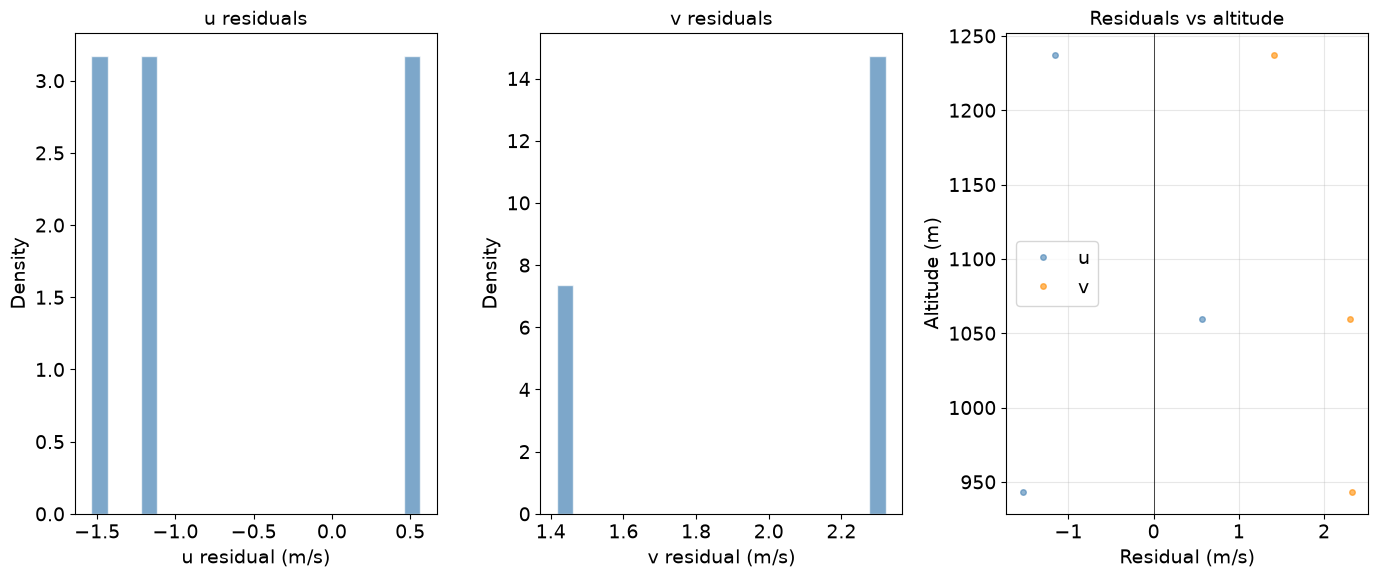

In [96]:
def compare_era5_to_glider(df_glider, ds, alt_levels=None,
                            lat_col='lat0', lon_col='lon0',
                            time_col='timestamp', alt_col='zhat',
                            u_col='uest', v_col='vest',
                            u_err_col='u_combined', v_err_col='v_combined',
                            max_alt_diff=100):

    # need to define alt_levels mapping pressure levels to approximate altitudes (m) for comparison.

    if alt_levels is None:
        # alt_levels = {975.1: 399.0, 950.0: 618.0, 925.0: 845.0, 900.0: 1074.0, 875.0: 1309.0, 850.0: 1544.0, 825.0: 1784.0, 804.5: 1992.0}
        alt_levels = {975.0: 301, 950.0: 528, 925.0: 751, 900.0: 975, 875.0: 1215.0, 850.0: 1450, 825.0: 1696, 804.5: 1943.0}

    results = []

    for _, row in df_glider.iterrows():

        # find nearest ERA5 altitude level
        nearest_pressure = min(alt_levels, 
                               key=lambda p: abs(alt_levels[p] - row[alt_col]))
        nearest_alt = alt_levels[nearest_pressure]
        print(nearest_alt)
        print(row[alt_col])
        # skip if too far from any ERA5 level
        if abs(nearest_alt - row[alt_col]) > max_alt_diff:
            continue
        
        print(abs(nearest_alt - row[alt_col]))
        # spatially interpolate to glider location
        # interpolate ERA5 model point (at closest glider altitude) to glider lat/lon position and time
        era5_point = ds.sel(pressure_level=nearest_pressure).interp(
            latitude=row[lat_col],
            longitude=row[lon_col],
            valid_time=np.datetime64(pd.Timestamp(row[time_col], unit='s')),
            method='linear'
        )
        print(f"era5_point {era5_point}")
        u_era5 = float(era5_point['u'].values)
        v_era5 = float(era5_point['v'].values)

        print(f"u_era5: {u_era5}")
        print(f"v_era5: {v_era5}")

        # exit()

        du = row[u_col] - u_era5
        dv = row[v_col] - v_era5
        zu = du / row[u_err_col]
        zv = dv / row[v_err_col]

        results.append({
            'alt':          row[alt_col],
            'era5_alt':     nearest_alt,
            'alt_diff':     abs(nearest_alt - row[alt_col]),
            'du':           du,
            'dv':           dv,
            'zu':           zu,
            'zv':           zv,
            'u_era5':       u_era5,
            'v_era5':       v_era5,
            'u_glider':     row[u_col],
            'v_glider':     row[v_col],
        })
    print(f"Results:\n {results}")

    print(f"Retained {len(results)}/{len(df_glider)} measurements within {max_alt_diff}m of an ERA5 level")
    return pd.DataFrame(results)

results_era5 = compare_era5_to_glider(df_clean, ds)
results_era5 = results_era5.dropna(subset=['u_era5', 'v_era5'])
print(f"Results ERA5 after dropna:\n {results_era5}")
print(f"Retained {len(results_era5)} valid comparisons")
# plotting residuals between the glider and ERA5 data NOT the radiosonde data
# the plot_sonde_comaprison function just plots the residuals - needs to be renamed
plot_sonde_comparison(results_era5)
plot_sonde_comparison_abs(results_era5)

In [209]:
print(results_era5.to_dict())

{'alt': {0: 982.6752, 1: 1035.558, 2: 943.2036, 3: 1059.6372, 4: 1237.1832, 5: 1432.2552}, 'era5_alt': {0: 975.0, 1: 975.0, 2: 975.0, 3: 975.0, 4: 1215.0, 5: 1450.0}, 'alt_diff': {0: 7.675200000000018, 1: 60.55799999999999, 2: 31.79639999999995, 3: 84.6371999999999, 4: 22.183199999999943, 5: 17.74479999999994}, 'du': {0: 2.0512324030148203, 1: 0.07415642403038802, 2: -1.5383543761065122, 3: 0.5640526912392403, 4: -1.1569265631526333, 5: -0.7134045504722142}, 'dv': {0: 1.8223397817394458, 1: 2.1417375682303077, 2: 2.3223467108573574, 3: 2.302952051399496, 4: 1.416774288329238, 5: 2.536516547803928}, 'zu': {0: 1.4702642394985186, 1: 0.05315318645547955, 2: -1.0354461781882538, 3: 0.37965647740974895, 4: -2.1956179912695437, 5: -0.30438127222350836}, 'zv': {0: 8.11300059683255, 1: 9.534949707746408, 2: 11.72938838673473, 3: 37.3292441028716, 4: 3.8354055879756546, 5: 9.392036605321076}, 'u_era5': {0: 8.56015478117758, 1: 8.564197201981917, 2: 8.558464025973267, 3: 8.557143107047576, 4: 8.

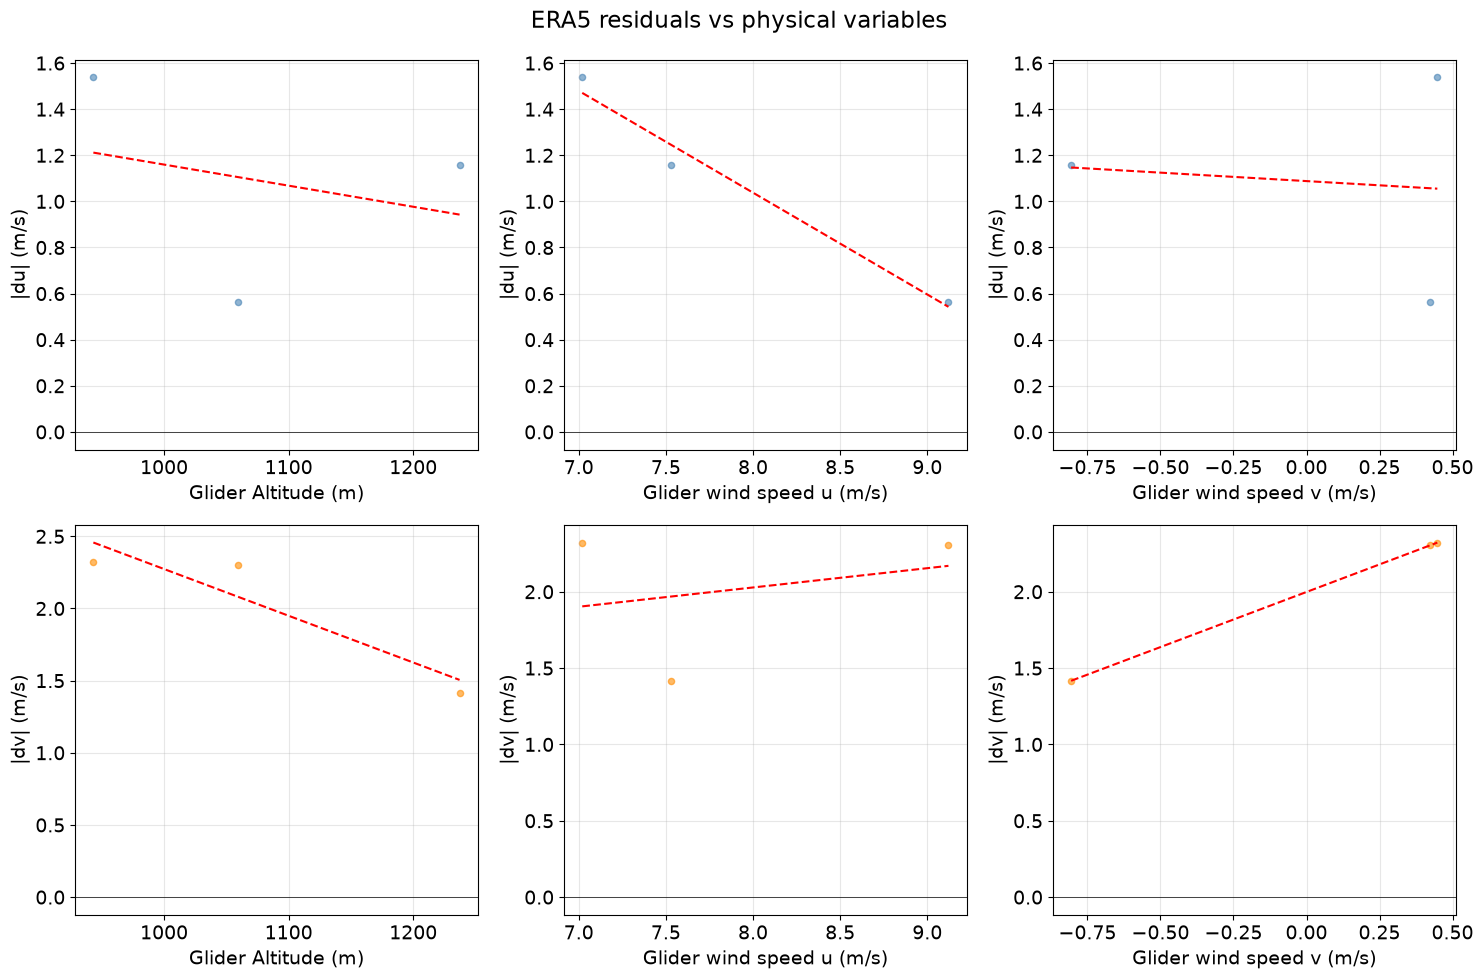

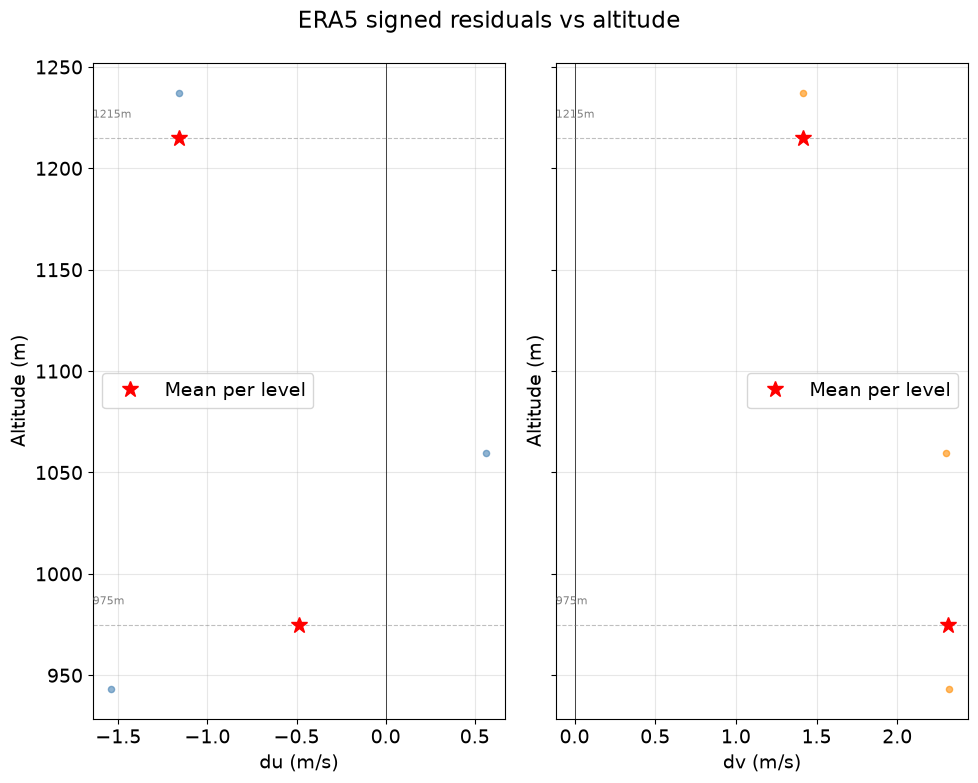

In [97]:
def plot_era5_residuals(results_df):
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle('ERA5 residuals vs physical variables')

    plot_params = [
        ('alt',       'Glider Altitude (m)',       axes[0, 0], axes[1, 0]),
        ('u_glider',  'Glider wind speed u (m/s)', axes[0, 1], axes[1, 1]),
        ('v_glider',  'Glider wind speed v (m/s)', axes[0, 2], axes[1, 2]),
    ]

    for x_col, x_label, ax_u, ax_v in plot_params:
        x = results_df[x_col]

        # du
        ax_u.scatter(x, results_df['du'].abs(), alpha=0.6, color='steelblue', s=20)
        ax_u.set_xlabel(x_label)
        ax_u.set_ylabel('|du| (m/s)')
        ax_u.axhline(0, color='k', linewidth=0.5)
        ax_u.grid(True, alpha=0.3)

        # dv
        ax_v.scatter(x, results_df['dv'].abs(), alpha=0.6, color='darkorange', s=20)
        ax_v.set_xlabel(x_label)
        ax_v.set_ylabel('|dv| (m/s)')
        ax_v.axhline(0, color='k', linewidth=0.5)
        ax_v.grid(True, alpha=0.3)

        # add linear trend to both
        for ax, col in [(ax_u, 'du'), (ax_v, 'dv')]:
            abs_resid = results_df[col].abs()
            mask = x.notna() & abs_resid.notna()
            if mask.sum() > 2:
                # obtaining best-fit parameters for the straight-line fit
                z = np.polyfit(x[mask], abs_resid[mask], 1)
                x_line = np.linspace(x.min(), x.max(), 100)
                # plotting the straight-line fit, using the best-fit parameters derived above
                ax.plot(x_line, np.polyval(z, x_line),
                        'r--', linewidth=1.5)

    fig.tight_layout()
    plt.show()


def plot_era5_bias_vs_alt(results_df):
    """Plot signed residuals vs altitude to show systematic bias at each ERA5 level."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8), sharey=True)
    fig.suptitle('ERA5 signed residuals vs altitude')

    # mark ERA5 pressure level altitudes
    era5_alts = results_df['era5_alt'].unique()

    for ax, col, label, color in [
        (ax1, 'du', 'du (m/s)', 'steelblue'),
        (ax2, 'dv', 'dv (m/s)', 'darkorange')
    ]:
        ax.scatter(results_df[col], results_df['alt'],
                   alpha=0.6, color=color, s=20)
        ax.axvline(0, color='k', linewidth=0.5)

        # mark ERA5 level altitudes
        for era5_alt in sorted(era5_alts):
            ax.axhline(era5_alt, color='grey', linewidth=0.8,
                       linestyle='--', alpha=0.5)
            ax.text(ax.get_xlim()[0] if ax.get_xlim()[0] != 0 else -5,
                    era5_alt + 10, f'{era5_alt:.0f}m',
                    fontsize=8, color='grey')

        # mean residual per ERA5 level
        for era5_alt in sorted(era5_alts):
            mask = results_df['era5_alt'] == era5_alt
            mean_resid = results_df.loc[mask, col].mean()
            ax.plot(mean_resid, era5_alt, 'r*', markersize=12,
                    label='Mean per level' if era5_alt == sorted(era5_alts)[0] else '')

        ax.set_xlabel(label)
        ax.set_ylabel('Altitude (m)')
        ax.grid(True, alpha=0.3)
        ax.legend()

    fig.tight_layout()
    plt.show()


# run both
plot_era5_residuals(results_era5)
plot_era5_bias_vs_alt(results_era5)

In [211]:
df_sonde.info()
print(df_sonde)
print(ds.sel(pressure_level=950).interp(
            latitude=sonde_row['LAT'] if 'LAT' in df_sonde.columns else 55.019,
            longitude=sonde_row['LON'] if 'LON' in df_sonde.columns else -1.878,
            valid_time=np.datetime64(pd.Timestamp('2026-03-22 23:15:00')),
            method='linear'
        ))
print(ds.sel(pressure_level=950)['u'].values)

<class 'pandas.DataFrame'>
RangeIndex: 191 entries, 0 to 190
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   magU       191 non-null    float64
 1   direction  191 non-null    float64
 2   alt        191 non-null    float64
 3   pres       191 non-null    float64
 4   u          191 non-null    float64
 5   v          191 non-null    float64
dtypes: float64(6)
memory usage: 9.1 KB
     magU  direction     alt    pres         u         v
0     1.1      315.0   160.0  1000.0  0.777817 -0.777817
1     2.7      291.0   163.0   999.7  2.520667 -0.967593
2     3.4      291.0   178.0   997.8  3.174173 -1.218451
3     3.9      292.0   189.0   996.7  3.616017 -1.460966
4     4.5      293.0   202.0   994.9  4.142272 -1.758290
..    ...        ...     ...     ...       ...       ...
186  10.8      303.0  1960.0   800.0  9.057642 -5.882102
187  10.8      303.0  1962.0   799.8  9.057642 -5.882102
188  10.8      303.0  1972.0   798

In [98]:
def compare_sonde_era5(df_sonde, ds, alt_levels=None):
    """
    Compare radiosonde wind speed with ERA5 at matching pressure levels.
    """
    if alt_levels is None:
        # alt_levels = {975.0: 399.0, 950.0: 618.0, 925.0: 845.0, 900.0: 1074.0, 875.0: 1309.0, 850.0: 1544.0, 825.0: 1784.0, 800.0: 1992.0}
        alt_levels = {975.0: 301, 950.0: 528, 925.0: 751, 900.0: 975, 875.0: 1215.0, 850.0: 1450, 825.0: 1696, 800: 1943.0}


    # radiosonde launch time - 23:15
    sonde_time = pd.Timestamp('2026-03-22 23:15:00')

    results = []

    for pressure, alt in alt_levels.items():
        # get nearest radiosonde measurement by altitude
        idx = (df_sonde['alt'] - alt).abs().idxmin()
        sonde_row = df_sonde.loc[idx]

        # get ERA5 at this pressure level, interpolated to sonde location
        # interpolate ERA5 model point (at closest radiosonde altitude) to radiosonde lat/lon position and time
        era5_point = ds.sel(pressure_level=pressure).interp(
            latitude=sonde_row['LAT'] if 'LAT' in df_sonde.columns else 55.019,
            longitude=sonde_row['LON'] if 'LON' in df_sonde.columns else -1.878,
            valid_time=np.datetime64(sonde_time),
            method='linear'
        )

        u_era5 = float(era5_point['u'].values)
        v_era5 = float(era5_point['v'].values)
        magU_era5 = np.sqrt(u_era5**2 + v_era5**2)

        # radiosonde wind in m/s
        magU_sonde = sonde_row['magU']

        results.append({
            'pressure':   pressure,
            'alt':        alt,
            'magU_sonde': magU_sonde,
            'magU_era5':  magU_era5,
            'u_era5':     u_era5,
            'v_era5':     v_era5,
            'diff':       magU_sonde - magU_era5,
        })

        print(f"{pressure} hPa (~{alt:.0f}m): "
              f"Sonde={magU_sonde:.2f} m/s, "
              f"ERA5={magU_era5:.2f} m/s, "
              f"Diff={magU_sonde - magU_era5:.2f} m/s")

    return pd.DataFrame(results)

sonde_era5_comparison = compare_sonde_era5(df_sonde, ds)
print(sonde_era5_comparison)

975.0 hPa (~301m): Sonde=7.70 m/s, ERA5=7.18 m/s, Diff=0.52 m/s
950.0 hPa (~528m): Sonde=8.30 m/s, ERA5=8.34 m/s, Diff=-0.04 m/s
925.0 hPa (~751m): Sonde=7.50 m/s, ERA5=7.06 m/s, Diff=0.44 m/s
900.0 hPa (~975m): Sonde=4.70 m/s, ERA5=5.17 m/s, Diff=-0.47 m/s
875.0 hPa (~1215m): Sonde=1.90 m/s, ERA5=4.04 m/s, Diff=-2.14 m/s
850.0 hPa (~1450m): Sonde=4.70 m/s, ERA5=4.87 m/s, Diff=-0.17 m/s
825.0 hPa (~1696m): Sonde=5.30 m/s, ERA5=6.78 m/s, Diff=-1.48 m/s
800 hPa (~1943m): Sonde=10.70 m/s, ERA5=9.04 m/s, Diff=1.66 m/s
   pressure     alt  magU_sonde  magU_era5    u_era5    v_era5      diff
0     975.0   301.0         7.7   7.175367  6.053904 -3.851770  0.524633
1     950.0   528.0         8.3   8.338558  5.376100 -6.374096 -0.038558
2     925.0   751.0         7.5   7.062086  3.788414 -5.959947  0.437914
3     900.0   975.0         4.7   5.172051  2.916541 -4.271288 -0.472051
4     875.0  1215.0         1.9   4.043180  2.838341 -2.879431 -2.143180
5     850.0  1450.0         4.7   4.871969

0     301.0
1     528.0
2     751.0
3     975.0
4    1215.0
5    1450.0
6    1696.0
7    1943.0
Name: alt, dtype: float64


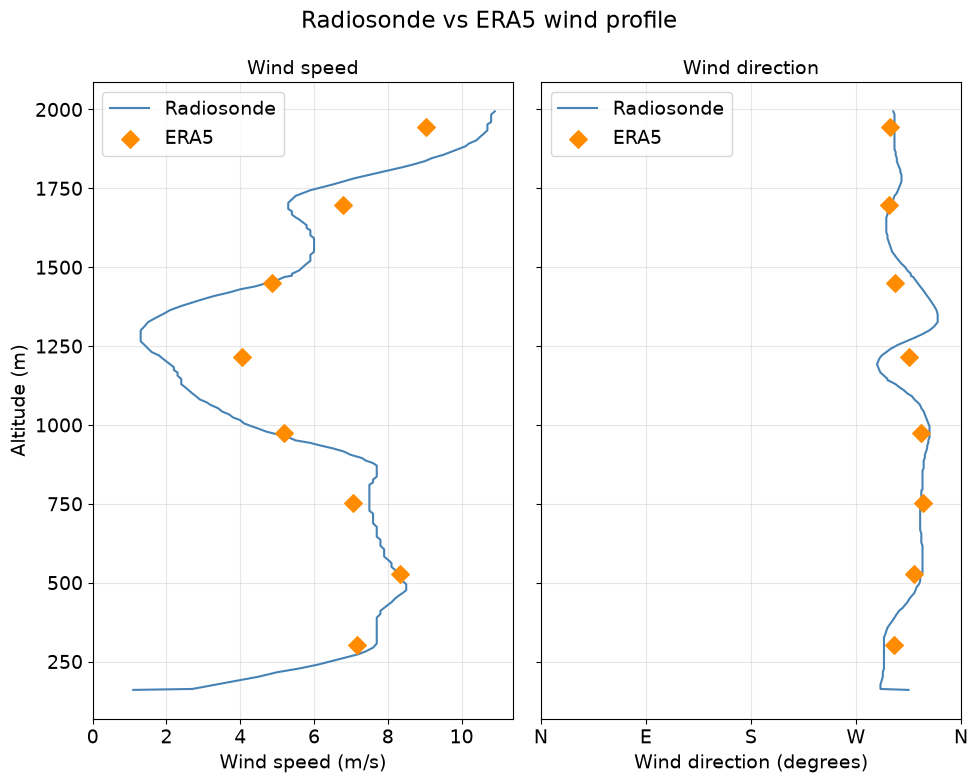

   pressure     alt  magU_sonde  dir_sonde  magU_era5    dir_era5    u_era5  \
0     975.0   301.0         7.7      294.0   7.175367  302.466379  6.053904   
1     950.0   528.0         8.3      326.0   8.338558  319.854734  5.376100   
2     925.0   751.0         7.5      326.0   7.062086  327.558100  3.788414   
3     900.0   975.0         4.7      333.0   5.172051  325.673773  2.916541   
4     875.0  1215.0         1.9      290.0   4.043180  315.411742  2.838341   
5     850.0  1450.0         4.7      323.0   4.871969  303.608066  4.057587   
6     825.0  1696.0         5.3      299.0   6.778148  298.350667  5.965162   
7     800.0  1943.0        10.7      303.0   9.038892  299.020057  7.904058   

     v_era5      diff  
0 -3.851770  0.524633  
1 -6.374096 -0.038558  
2 -5.959947  0.437914  
3 -4.271288 -0.472051  
4 -2.879431 -2.143180  
5 -2.696678 -0.171969  
6 -3.218716 -1.478148  
7 -4.384909  1.661108  


In [103]:
def compare_sonde_era5(df_sonde, ds, alt_levels=None,
                        sonde_lat=55.019, sonde_lon=-1.878,
                        sonde_time=pd.Timestamp('2026-03-22 23:15:00')):
    """
    Compare radiosonde wind profile with ERA5 at matching pressure levels.
    Plots ERA5 wind speed and direction overlaid on the radiosonde profile.
    """
    if alt_levels is None:
        alt_levels = {975.0: 301, 950.0: 528, 925.0: 751, 900.0: 975,
                      875.0: 1215.0, 850.0: 1450, 825.0: 1696, 800.0: 1943.0}

    results = []

    for pressure, alt in alt_levels.items():
        idx      = (df_sonde['alt'] - alt).abs().idxmin()
        sonde_row = df_sonde.loc[idx]

        # interpolate ERA5 model point (at closest radiosonde altitude) to radiosonde lat/lon position and time
        era5_point = ds.sel(pressure_level=pressure, method='nearest').interp(
            latitude=sonde_row['LAT'] if 'LAT' in df_sonde.columns else sonde_lat,
            longitude=sonde_row['LON'] if 'LON' in df_sonde.columns else sonde_lon,
            valid_time=np.datetime64(sonde_time),
            method='linear'
        )

        u_era5    = float(era5_point['u'].values)
        v_era5    = float(era5_point['v'].values)
        magU_era5 = np.sqrt(u_era5**2 + v_era5**2)
        dir_era5  = (270 - np.rad2deg(np.arctan2(v_era5, u_era5))) % 360

        results.append({
            'pressure':   pressure,
            'alt':        alt,
            'magU_sonde': sonde_row['magU'],
            'dir_sonde':  sonde_row['direction'] if 'direction' in df_sonde.columns else np.nan,
            'magU_era5':  magU_era5,
            'dir_era5':   dir_era5,
            'u_era5':     u_era5,
            'v_era5':     v_era5,
            'diff':       sonde_row['magU'] - magU_era5,
        })

    results_df = pd.DataFrame(results)

    # print(df_sonde['magU'])
    # print(df_sonde['alt'])

    print(results_df['alt'])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8), sharey=True)
    fig.suptitle('Radiosonde vs ERA5 wind profile')

    # wind speed
    ax1.plot(df_sonde['magU'], df_sonde['alt'],
             color='steelblue', linewidth=1.5, label='Radiosonde')
    ax1.scatter(results_df['magU_era5'], results_df['alt'],
                color='darkorange', s=80, marker='D', zorder=5,
                label='ERA5')
    ax1.set_xlabel('Wind speed (m/s)')
    ax1.set_ylabel('Altitude (m)')
    ax1.set_title('Wind speed')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim(left=0)

    # wind direction
    if 'direction' in df_sonde.columns:
        ax2.plot(df_sonde['direction'], df_sonde['alt'],
                 color='steelblue', linewidth=1.5, label='Radiosonde')
    ax2.scatter(results_df['dir_era5'], results_df['alt'],
                color='darkorange', s=80, marker='D', zorder=5,
                label='ERA5')
    ax2.set_xlabel('Wind direction (degrees)')
    ax2.set_title('Wind direction')
    ax2.set_xlim(0, 360)
    ax2.set_xticks([0, 90, 180, 270, 360])
    ax2.set_xticklabels(['N', 'E', 'S', 'W', 'N'])
    ax2.legend()
    ax2.grid(True, alpha=0.3)   

    fig.tight_layout()
    plt.show()

    return results_df

sonde_era5_comparison = compare_sonde_era5(df_sonde, ds)
print(sonde_era5_comparison)

In [104]:
print((results_era5['zv'].abs() < 5).mean())
print(results_era5['zv'])
print(results_era5['zv'].abs() < 2)

0.3333333333333333
0    11.729388
1    37.329244
2     3.835406
Name: zv, dtype: float64
0    False
1    False
2    False
Name: zv, dtype: bool


In [108]:
# check what fraction are within more relaxed thresholds
for threshold in [1, 2, 5, 10]:
    frac_u = (results_era5['zu'].abs() < threshold).mean()
    frac_v = (results_era5['zv'].abs() < threshold).mean()
    print(f"|z| < {threshold}: u={frac_u*100:.1f}%, v={frac_v*100:.1f}%")

# identify the outliers
outliers = results_era5[results_era5['zu'].abs() > 10]
print(f"\n{len(outliers)} outliers with |zu| > 10")
# print(outliers[['alt', 'era5_alt', 'alt_diff', 'du', 'dv', 'u_glider', 'u_era5']])
print(outliers)

|z| < 1: u=33.3%, v=0.0%
|z| < 2: u=66.7%, v=0.0%
|z| < 5: u=100.0%, v=33.3%
|z| < 10: u=100.0%, v=33.3%

0 outliers with |zu| > 10
Empty DataFrame
Columns: [alt, era5_alt, alt_diff, du, dv, zu, zv, u_era5, v_era5, u_glider, v_glider]
Index: []


In [107]:
print("ERA5 grid extent:")
print(f"Latitude: {float(ds.latitude.min()):.2f} to {float(ds.latitude.max()):.2f}")
print(f"Longitude: {float(ds.longitude.min()):.2f} to {float(ds.longitude.max()):.2f}")

print("\nGlider data extent:")
print(f"Latitude: {df_clean['lat0'].min():.2f} to {df_clean['lat0'].max():.2f}")
print(f"Longitude: {df_clean['lon0'].min():.2f} to {float(df_clean['lon0'].max()):.2f}")

ERA5 grid extent:
Latitude: 55.00 to 57.00
Longitude: -4.00 to -1.00

Glider data extent:
Latitude: 56.19 to 56.22
Longitude: -3.34 to -3.31
